<h1  align="center"> Previsão do estado de saúde do feto</h1>
<h5 align="center">Isabela Leme Cruz</h5>
<h5 align="center">Turma 26 - 2°Semestre</h5>
<h5 align="center">Ilum Escola de Ciência (CNPEM)</h5>
<h5 align="center">Aprendizado de máquina</h5>
<h5 align="center">Professor Doutor responsável pela disciplina: Daniel Roberto Cassar.</h5>

<h1 align="center">Tiamat</h1>
<h2>Introdução</h2>

<p align="justify"> A cardiotocografia (CTG) é um exame amplamente utilizado no acompanhamento da gestação e do parto, pois registra continuamente a frequência cardíaca fetal e as contrações uterinas. A interpretação desse exame, porém, depende da experiência do profissional e pode variar entre observadores, tornando relevante o desenvolvimento de métodos capazes de auxiliar na identificação precoce de fetos em risco. Nesse contexto, técnicas de <strong>aprendizado de máquina</strong> podem ser utilizadas para aprender padrões a partir de medidas extraídas do exame e realizar tarefas de classificação. </p>

<p align="justify"> Entre os algoritmos de classificação, métodos como <strong>regressão logística</strong>, <strong>k-vizinhos mais próximos (k-NN)</strong>, <strong>máquinas de vetores de suporte (SVM)</strong>, <strong>Random Forest</strong> e <strong>Gradient Boosting</strong> apresentam abordagens distintas para separar as classes, e seu desempenho depende de fatores como a escala dos atributos, a correlação entre variáveis, o desbalanceamento das classes e a escolha dos hiperparâmetros. Por isso, a comparação entre eles deve ser feita de forma criteriosa, com <strong>validação cruzada</strong> e <strong>otimização de hiperparâmetros</strong> realizada sem vazamento de dados. </p>

<p align="justify"> Neste trabalho, é utilizado o conjunto de dados <strong>Fetal Health Classification</strong>, disponibilizado no Kaggle a partir de dados de cardiotocografia do UCI Machine Learning Repository, contendo 21 atributos extraídos de 2.126 exames. O objetivo é classificar o <strong>estado de saúde fetal</strong> em três categorias (<strong>normal, suspeito ou patológico</strong>), conforme o rótulo atribuído por obstetras especialistas, comparando o desempenho de diferentes algoritmos e pipelines otimizados com o <strong>Optuna</strong>. Por se tratar de um problema multiclasse desbalanceado, a avaliação prioriza métricas como F1-macro e recall da classe patológica, além de discutir a interpretabilidade dos modelos obtidos. </p>

<p style="text-align: justify;">
<strong>optuna:</strong> Utilizada para realizar a otimização de hiperparâmetros dos algoritmos, testando diferentes combinações de valores de forma inteligente e registrando o desempenho de cada tentativa.
</p>

<p style="text-align: justify;">
<strong>optuna.create_study:</strong> Utilizada para criar o estudo de otimização de cada algoritmo, definindo que o objetivo é maximizar a métrica escolhida e permitindo salvar as tentativas em um arquivo, para que a busca possa ser retomada sem repetir o trabalho.
</p>

<p style="text-align: justify;">
<strong>optuna.samplers.TPESampler:</strong> Utilizada para definir o método de sorteio dos hiperparâmetros (TPE), que concentra as próximas tentativas nas regiões do espaço de busca que apresentaram melhores resultados nas tentativas anteriores.
</p>

<p style="text-align: justify;">
<strong>optuna.visualization:</strong> Utilizada para criar os gráficos do histórico de otimização e da importância de cada hiperparâmetro, auxiliando na interpretação da busca realizada.
</p>

<p style="text-align: justify;">
<strong>functools.partial:</strong> Utilizada para fixar alguns argumentos da função objetivo (algoritmo, atributos e alvo), deixando livre apenas o argumento que o Optuna fornece a cada tentativa.
</p>

<p style="text-align: justify;">
<strong>sklearn.pipeline.make_pipeline:</strong> Utilizada para encadear normalização, redução de dimensionalidade e classificador em um único fluxo, garantindo que cada etapa seja ajustada apenas com os dados de treino de cada divisão da validação cruzada.
</p>

<p style="text-align: justify;">
<strong>sklearn.preprocessing.RobustScaler:</strong> Utilizada para normalizar os atributos usando a mediana e o intervalo interquartil, o que a torna menos sensível a valores extremos (outliers) do que a padronização tradicional.
</p>

<p style="text-align: justify;">
<strong>sklearn.preprocessing.MinMaxScaler:</strong> Utilizada para reescalar cada atributo para o intervalo entre 0 e 1, mantendo a forma original da distribuição dos dados.
</p>

<p style="text-align: justify;">
<strong>sklearn.decomposition.PCA:</strong> Utilizada para reduzir a dimensionalidade dos dados, combinando os atributos originais, que são redundantes entre si, em um número menor de componentes não correlacionados.
</p>

<p style="text-align: justify;">
<strong>sklearn.feature_selection.RFE:</strong> Utilizada para selecionar atributos por eliminação recursiva, removendo a cada etapa os atributos menos importantes segundo um modelo auxiliar, até restar o número de atributos definido.
</p>

<p style="text-align: justify;">
<strong>sklearn.neighbors.KNeighborsClassifier:</strong> Utilizada para implementar o algoritmo k-NN, que classifica um exame de acordo com a classe mais frequente entre os exames mais próximos do conjunto de treino.
</p>

<p style="text-align: justify;">
<strong>sklearn.svm.SVC:</strong> Utilizada para implementar a máquina de vetores de suporte, que busca a fronteira de maior margem entre as classes e, com kernels não lineares, consegue fronteiras de decisão curvas.
</p>

<p style="text-align: justify;">
<strong>sklearn.ensemble.RandomForestClassifier:</strong> Utilizada para implementar o Random Forest, um conjunto de árvores de decisão treinadas de forma independente em amostras diferentes dos dados, cujas previsões são combinadas por votação.
</p>

<p style="text-align: justify;">
<strong>sklearn.ensemble.HistGradientBoostingClassifier:</strong> Utilizada para implementar o Gradient Boosting baseado em histogramas, que treina árvores em sequência, cada uma corrigindo os erros das anteriores, de forma mais rápida do que a versão tradicional.
</p>

In [1]:

import warnings
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import optuna
import optuna.visualization as vis
from functools import partial
from optuna import create_study
from optuna.samplers import TPESampler
from optuna.visualization.matplotlib import plot_optimization_history

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import RFE
from sklearn.metrics import make_scorer, recall_score, ConfusionMatrixDisplay
from sklearn.exceptions import ConvergenceWarning
from matplotlib.collections import PathCollection
from matplotlib.lines import Line2D
from optuna.visualization.matplotlib import plot_optimization_history

from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score)
from sklearn.inspection import permutation_importance
from matplotlib.patches import Patch
optuna.logging.set_verbosity(optuna.logging.WARNING)

<h2>Conjunto de dados e descrição do dataset</h2>

<p align="justify"> O conjunto de dados utilizado neste trabalho é o <strong>Fetal Health Classification</strong>, obtido na plataforma Kaggle a partir de dados de cardiotocografia do UCI Machine Learning Repository. Ele reúne <strong>2.126 exames</strong> de cardiotocografia, cada um descrito por <strong>21 atributos numéricos</strong> extraídos do registro da frequência cardíaca fetal e das contrações uterinas, como frequência basal, acelerações, desacelerações, movimentos fetais, medidas de variabilidade de curto e longo prazo e estatísticas do histograma da frequência cardíaca. </p>

<p align="justify"> A variável alvo, <code>fetal_health</code>, indica o estado de saúde fetal em três classes: <strong>normal (1)</strong>, <strong>suspeito (2)</strong> e <strong>patológico (3)</strong>. Esses rótulos foram atribuídos por três obstetras especialistas, de modo que o objetivo dos modelos é reproduzir o julgamento clínico a partir das medidas do exame. As classes são <strong>desbalanceadas</strong>, com predominância de exames normais, o que influencia a escolha das métricas de avaliação e da estratégia de validação. </p>

<p align="justify"> O arquivo <code>fetal_health.csv</code> foi baixado manualmente do Kaggle e armazenado na mesma pasta do notebook, sendo carregado com a biblioteca <strong>pandas</strong> e armazenado em um <em>DataFrame</em>. Essa abordagem garante a reprodutibilidade do código sem depender de autenticação ou de conexão com a plataforma. Após o carregamento, foi realizada uma checagem inicial do conjunto de dados, verificando suas dimensões, os tipos das variáveis, a presença de valores ausentes e de linhas duplicadas, além da distribuição das classes do alvo. </p>

In [2]:
df = pd.read_csv("fetal_health.csv")
print(df.shape)
df.info()
print(df.isna().sum().sum())                      
print("Duplicatas:", df.duplicated().sum())      
print(df["fetal_health"].value_counts().sort_index())                        
print(df["fetal_health"].value_counts(normalize=True).sort_index().round(3)) 

(2126, 22)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2126 entries, 0 to 2125
Data columns (total 22 columns):
 #   Column                                                  Non-Null Count  Dtype  
---  ------                                                  --------------  -----  
 0   baseline value                                          2126 non-null   float64
 1   accelerations                                           2126 non-null   float64
 2   fetal_movement                                          2126 non-null   float64
 3   uterine_contractions                                    2126 non-null   float64
 4   light_decelerations                                     2126 non-null   float64
 5   severe_decelerations                                    2126 non-null   float64
 6   prolongued_decelerations                                2126 non-null   float64
 7   abnormal_short_term_variability                         2126 non-null   float64
 8   mean_value_of_short_term_va

<p align="justify"> A checagem inicial mostrou que o conjunto de dados possui <strong>2.126 linhas e 22 colunas</strong>, sendo 21 atributos preditivos e 1 variável alvo. Todas as colunas são do tipo numérico (<code>float64</code>) e nenhuma apresenta <strong>valores ausentes</strong>, o que dispensa etapas de imputação. Foram identificadas <strong>13 linhas duplicadas</strong>, que serão tratadas antes da divisão entre treino e teste, para evitar que um mesmo exame apareça nos dois conjuntos e cause vazamento de dados. </p>

<p align="justify"> A distribuição da variável alvo <code>fetal_health</code> evidencia o <strong>desbalanceamento das classes</strong>: <strong>1.655 exames normais (77,8%)</strong>, <strong>295 suspeitos (13,9%)</strong> e <strong>176 patológicos (8,3%)</strong>. Isso significa que um classificador que sempre prevê "normal" já alcançaria cerca de 78% de acurácia sem aprender nada, razão pela qual a avaliação não deve se basear apenas na acurácia. Serão utilizadas métricas como F1-macro, balanced accuracy e recall da classe patológica, além de validação cruzada estratificada, que preserva a proporção das classes em cada divisão. </p>

>
<h4>Dicionário de Dados</h4>

<ul>
    <li><b>baseline value</b>: frequência cardíaca fetal basal, em batimentos por minuto (numérico).</li>
    <li><b>accelerations</b>: número de acelerações da frequência cardíaca fetal por segundo (numérico).</li>
    <li><b>fetal_movement</b>: número de movimentos fetais por segundo (numérico).</li>
    <li><b>uterine_contractions</b>: número de contrações uterinas por segundo (numérico).</li>
    <li><b>light_decelerations</b>: número de desacelerações leves por segundo (numérico).</li>
    <li><b>severe_decelerations</b>: número de desacelerações severas por segundo (numérico).</li>
    <li><b>prolongued_decelerations</b>: número de desacelerações prolongadas por segundo (numérico). O nome mantém a grafia original do dataset.</li>
    <li><b>abnormal_short_term_variability</b>: porcentagem do tempo com variabilidade de curto prazo anormal (numérico).</li>
    <li><b>mean_value_of_short_term_variability</b>: valor médio da variabilidade de curto prazo (numérico).</li>
    <li><b>percentage_of_time_with_abnormal_long_term_variability</b>: porcentagem do tempo com variabilidade de longo prazo anormal (numérico).</li>
    <li><b>mean_value_of_long_term_variability</b>: valor médio da variabilidade de longo prazo (numérico).</li>
    <li><b>histogram_width</b>: largura do histograma da frequência cardíaca fetal (numérico).</li>
    <li><b>histogram_min</b>: valor mínimo do histograma (numérico).</li>
    <li><b>histogram_max</b>: valor máximo do histograma (numérico).</li>
    <li><b>histogram_number_of_peaks</b>: número de picos do histograma (numérico discreto).</li>
    <li><b>histogram_number_of_zeroes</b>: número de zeros do histograma (numérico discreto).</li>
    <li><b>histogram_mode</b>: moda do histograma (numérico).</li>
    <li><b>histogram_mean</b>: média do histograma (numérico).</li>
    <li><b>histogram_median</b>: mediana do histograma (numérico).</li>
    <li><b>histogram_variance</b>: variância do histograma (numérico).</li>
    <li><b>histogram_tendency</b>: tendência do histograma (categórico ordinal; -1 = assimétrico à esquerda, 0 = simétrico, 1 = assimétrico à direita).</li>
    <li><b>fetal_health</b>: variável alvo do problema, atribuída por três obstetras especialistas. Neste trabalho, os valores são:
    <ul>
        <li>1 = normal;</li>
        <li>2 = suspeito;</li>
        <li>3 = patológico.</li>
    </ul>
    </li>
</ul>

<p style="text-align:justify">Os atributos incluem medidas da frequência cardíaca fetal, eventos de aceleração e desaceleração, movimentos fetais, contrações uterinas e estatísticas do histograma do exame de cardiotocografia. Eles serão utilizados pelos algoritmos de aprendizado de máquina para identificar padrões associados ao estado de saúde fetal.</p>

<h2>Análise dos dados</h2>

<h3>Preparação dos dados</h3>

<p align="justify"> Nesta etapa, os dados são preparados para a análise exploratória. Na inspeção inicial, observou-se que a coluna <code>baseline value</code> era a única com <strong>espaço no nome</strong>, fugindo do padrão das demais, que utilizam <em>underscore</em> (por exemplo, <code>fetal_movement</code>). Esse tipo de nome pode gerar erros em etapas posteriores, como na seleção de colunas, na construção de pipelines e na identificação de atributos nos gráficos de explicação do modelo. Por isso, a coluna foi renomeada para <code>baseline_value</code>. </p>

<p align="justify"> Além disso, a variável alvo <code>fetal_health</code>, originalmente armazenada como <code>float64</code> (1.0, 2.0 e 3.0), foi convertida para <strong>inteiro</strong>, pois representa categorias e não uma medida contínua. Por fim, foram definidos um dicionário que associa cada valor do alvo ao nome da classe (normal, suspeito e patológico) e a ordem de exibição das classes, para que os gráficos sejam mais legíveis e sigam a sequência de gravidade. Também foi configurado o tema visual dos gráficos (<code>seaborn</code>, estilo <code>whitegrid</code>). </p>

In [3]:


df = pd.read_csv("fetal_health.csv")
df = df.rename(columns={"baseline value": "baseline_value"})
df["fetal_health"] = df["fetal_health"].astype(int)

nomes_classes = {1: "Normal", 2: "Suspeito", 3: "Patológico"}
ordem = ["Normal", "Suspeito", "Patológico"]

<h3>Duplicatas: identificando e removendo</h3>

No código abaixo, as duplicatas são identificadas e removidas, afim de não causar vazamento de dados.

In [4]:
atributos = [c for c in df.columns if c != "fetal_health"]

dup = df[df.duplicated(keep=False)]
print("Linhas envolvidas em duplicatas:", len(dup))
print("Linhas excedentes (a remover):", df.duplicated().sum())
print("\nClasses das linhas duplicadas:")
print(dup["fetal_health"].value_counts().sort_index())

conflitos = dup.groupby(atributos)["fetal_health"].nunique()
print("\nGrupos de duplicatas com rótulos conflitantes:", (conflitos > 1).sum())

df = df.drop_duplicates().reset_index(drop=True)
print("\nNovo formato:", df.shape)

Linhas envolvidas em duplicatas: 24
Linhas excedentes (a remover): 13

Classes das linhas duplicadas:
fetal_health
1    16
2     6
3     2
Name: count, dtype: int64

Grupos de duplicatas com rótulos conflitantes: 0

Novo formato: (2113, 22)


<p align="justify"> Foram identificadas <strong>13 linhas duplicadas</strong>, isto é, exames com os 21 atributos e o rótulo idênticos a outro. Como os atributos são medidas contínuas, é improvável que valores idênticos em todas as colunas ocorram por coincidência, o que sugere registros repetidos. Duplicatas não acrescentam informação nova e, se distribuídas entre treino e teste, fazem o modelo ser avaliado em exemplos que já viu, gerando <strong>vazamento de dados</strong> e estimativas otimistas de desempenho. Por isso, optou-se por <strong>removê-las</strong> antes da divisão entre treino e teste, o que reduziu o conjunto de 2.126 para 2.113 exames (perda de cerca de 0,6%). Verificou-se também que nenhhuma duplicata possuía rótulo conflitante. </p>

<h3>Distribuição do target</h3>

<p align="justify"> Antes de treinar qualquer modelo, é importante conhecer a distribuição do target <code>fetal_health</code>, isto é, quantos exames pertencem a cada classe (normal, suspeito e patológico). Para isso, será construído um gráfico de barras com a contagem e o percentual de exames de cada classe. </p>

<p align="justify"> Essa verificação é necessária porque a proporção entre as classes influencia diretamente as decisões de modelagem. Se uma classe for muito mais frequente que as outras, um modelo pode alcançar alta acurácia apenas prevendo sempre a classe majoritária, sem aprender a identificar os casos suspeitos e patológicos, que são os mais relevantes clinicamente. Conhecer o desbalanceamento permite escolher métricas adequadas (como F1-macro e balanced accuracy), usar validação cruzada estratificada e avaliar o uso de pesos de classe. </p>

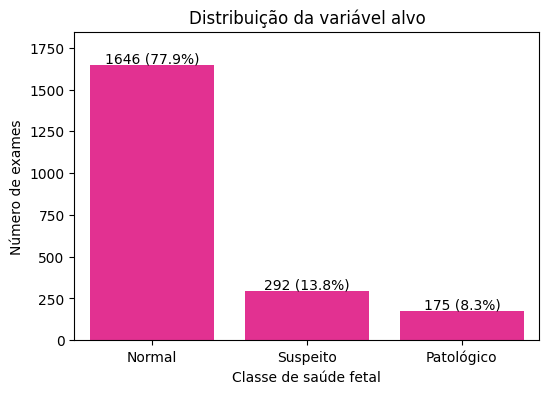

In [5]:
contagem = df["fetal_health"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=[nomes_classes[i] for i in contagem.index], y=contagem.values, ax=ax, color="deeppink")
for i, v in enumerate(contagem.values):
    ax.text(i, v + 15, f"{v} ({v / len(df):.1%})", ha="center")
ax.set_ylim(0, contagem.max() * 1.12)
ax.set_xlabel("Classe de saúde fetal")
ax.set_ylabel("Número de exames")
ax.set_title("Distribuição da variável alvo")
plt.show()

<p align="justify"> <strong>Distribuição do target:</strong> Após a remoção das duplicatas, aproximadamente 77,9% dos exames são normais, 13,8% são suspeitos e 8,3% são patológicos. A predominância da classe normal confirma o desbalanceamento do conjunto e justifca a utilização de validação cruzada estratificada e de metricas que não dependam exclusivamente da acurácia. </p>

<h3>Distribuição de todos os atributos</h3>

<p align="justify"> Antes de focar nos atributos mais relevantes, serão construídos histogramas de <strong>todos os 21 atributos</strong>, para ter uma visão geral do formato de cada variável. Essa inspeção permite identificar atributos assimétricos, com muitos valores iguais a zero, com escalas muito diferentes ou com valores discretos, o que orienta decisões de pré-processamento, como a necessidade de escalonamento para modelos baseados em distância (k-NN, SVM) e regressão logística. </p>

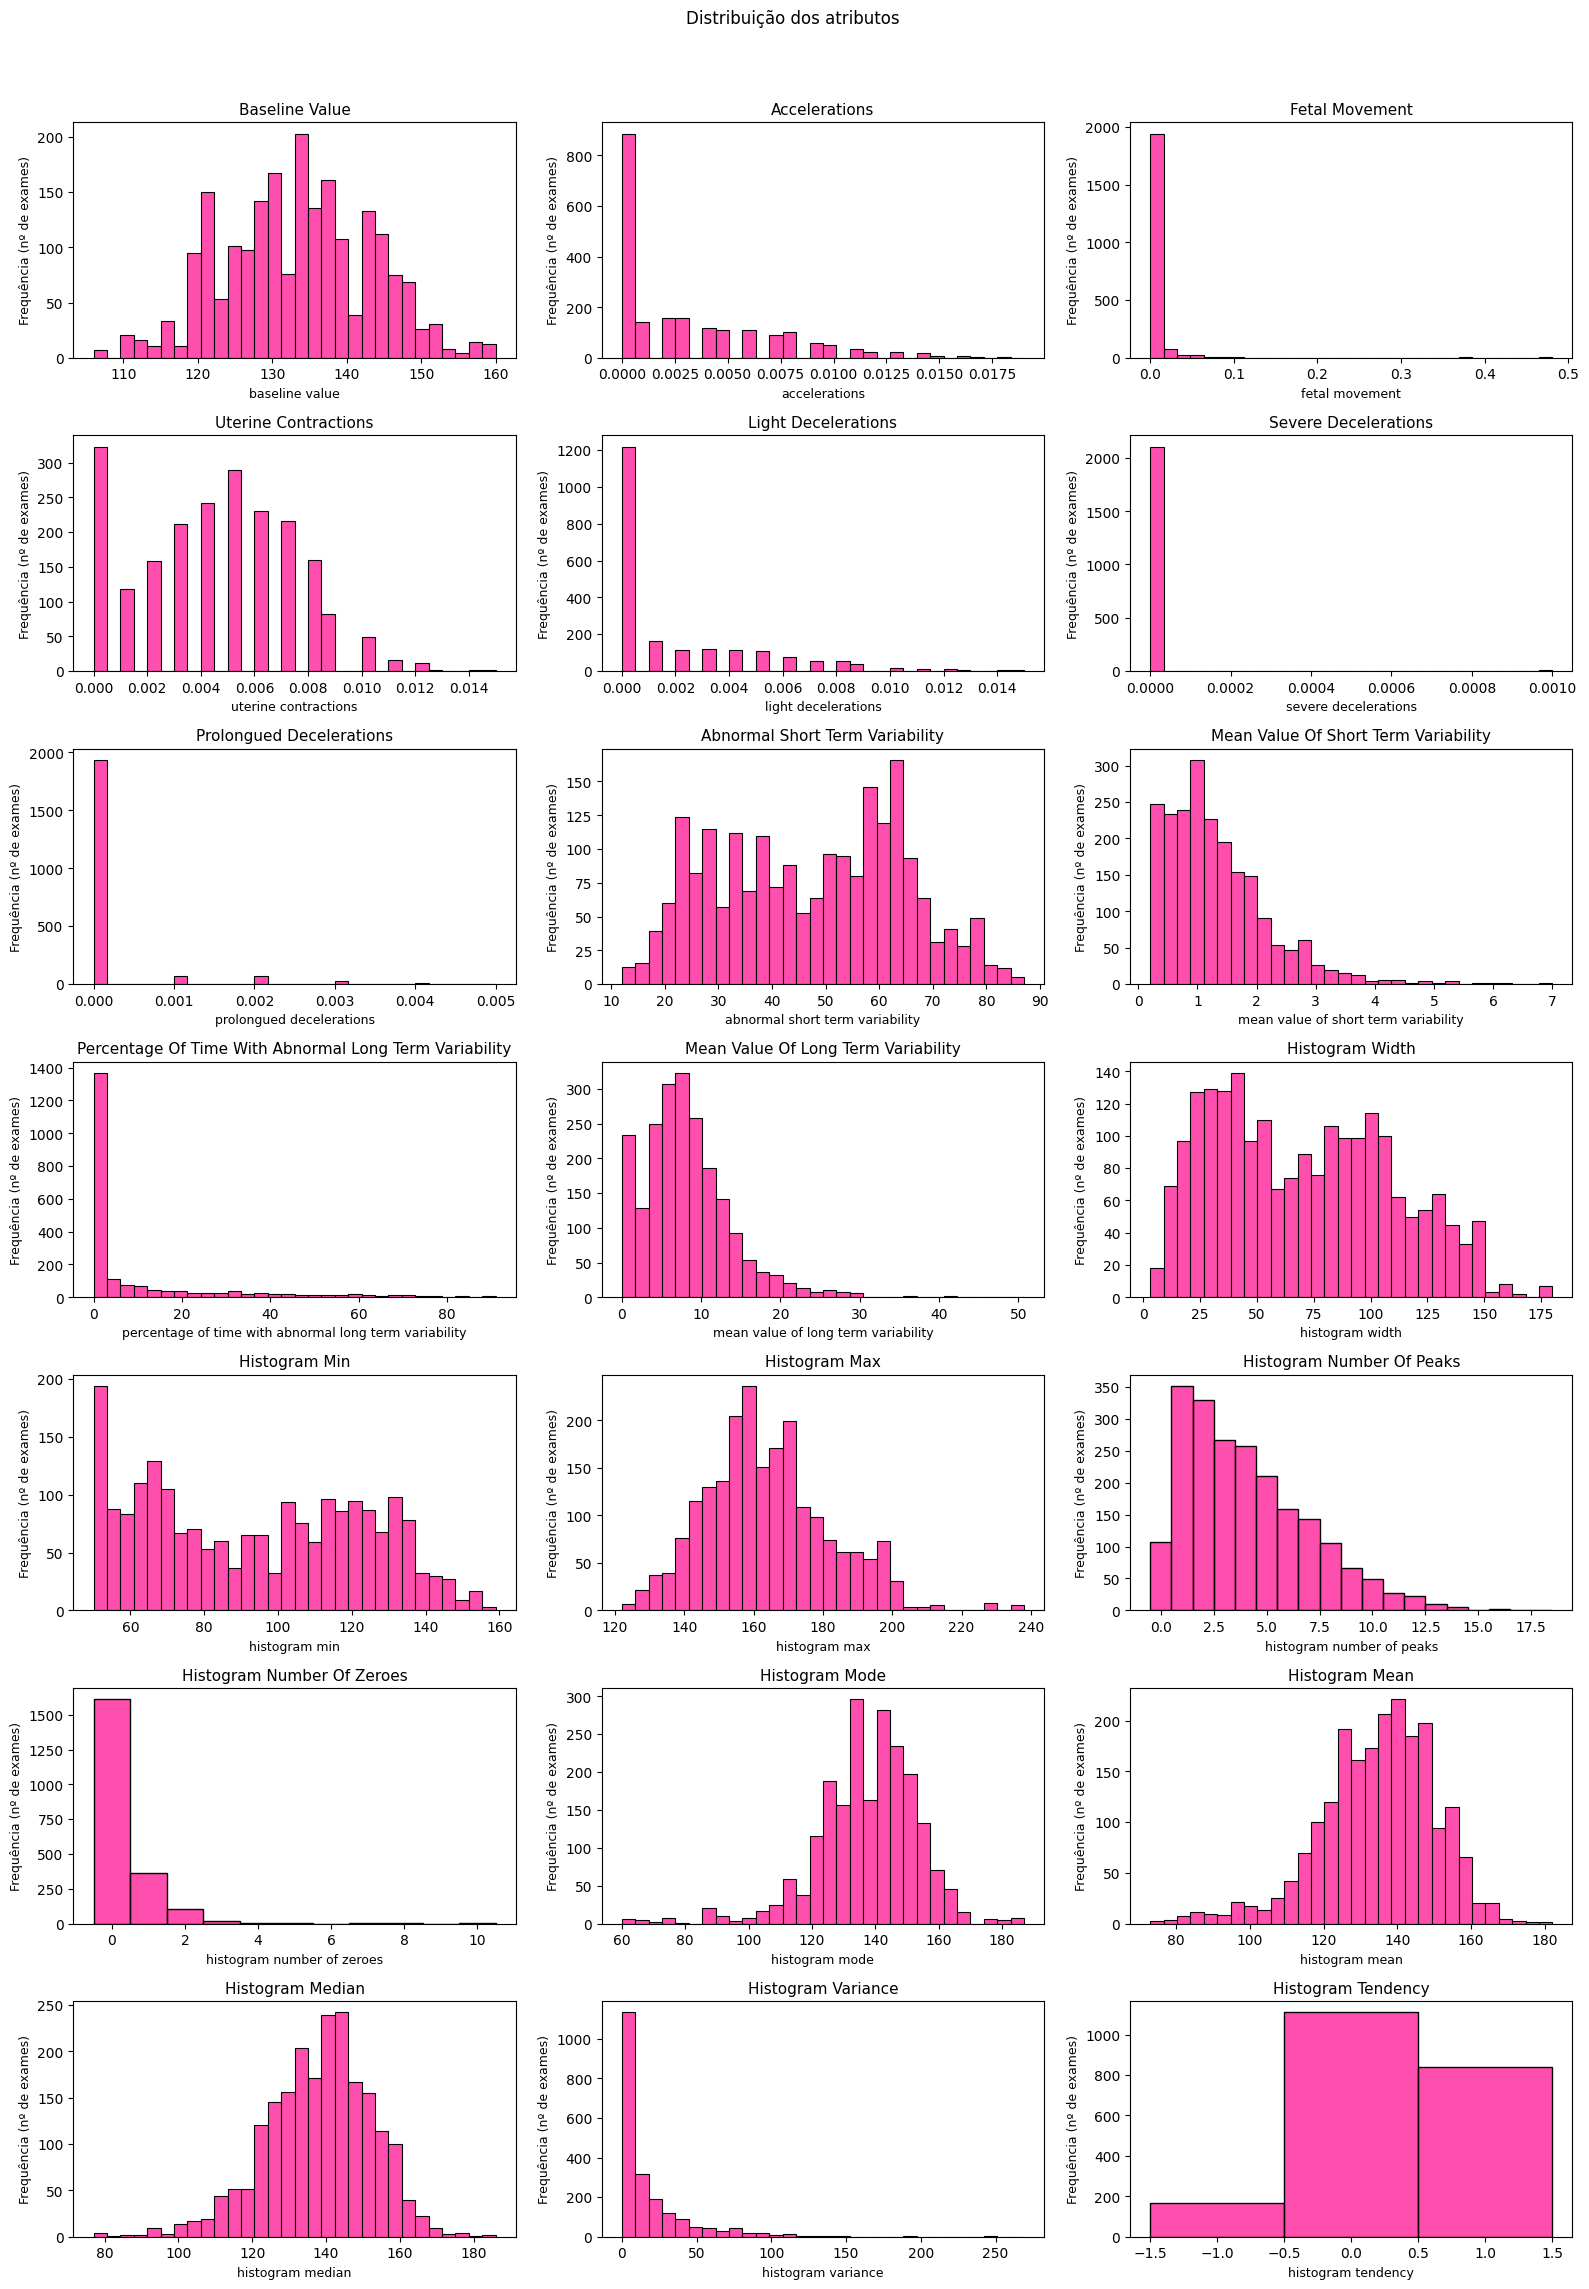

In [6]:
atributos = [c for c in df.columns if c != "fetal_health"]
discretos = ["histogram_number_of_peaks", "histogram_number_of_zeroes", "histogram_tendency"]

n_cols = 3
n_rows = int(np.ceil(len(atributos) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.2 * n_rows))

for ax, col in zip(axes.ravel(), atributos):
    if col in discretos:
        sns.histplot(df[col], discrete=True, ax=ax, color="deeppink")
    else:
        sns.histplot(df[col], bins=30, ax=ax, color="deeppink")

    titulo = col.replace("_", " ").title()

    ax.set_title(titulo, fontsize=11, )
    ax.set_xlabel(col.replace("_", " "), fontsize=9)
    ax.set_ylabel("Frequência (nº de exames)", fontsize=9)

for ax in axes.ravel()[len(atributos):]:
    ax.set_visible(False)

fig.suptitle("Distribuição dos atributos ", y=1.02)
plt.tight_layout()
plt.show()



<p align="justify">
A análise dos histogramas indica que os atributos do conjunto de dados apresentam distribuições bastante distintas. Algumas variáveis, como <strong>mean_hue_value</strong>, <strong>histogram_std</strong>, <strong>histogram_mean</strong> e <strong>histogram_mode</strong>, exibem distribuições aproximadamente simétricas, com maior concentração de observações próximas aos valores centrais. Esse comportamento sugere uma maior homogeneidade dessas características entre as amostras analisadas.
</p>

<p align="justify">
Em contraste, atributos relacionados aos movimentos fetais e às desacelerações cardíacas, como: <strong>acceleration</strong>, <strong>fetal_movement</strong>, <strong>light_decelerations</strong>, <strong>severe_decelerations</strong> e <strong>prolonged_decelerations</strong>, apresentam elevada assimetria positiva. A maioria dos registros concentra-se em valores próximos de zero, indicando que esses eventos ocorrem com baixa frequência na maior parte dos exames, enquanto valores elevados aparecem apenas em poucos casos.
</p>

<p align="justify">
As variáveis associadas à variabilidade da frequência cardíaca fetal, como <strong>abnormal_short_term_variability</strong>, <strong>mean_value_of_short_term_variability</strong>, <strong>percentage_of_time_with_abnormal+long_term_variability</strong> e <strong>mean_value_of_long_term_variability</strong>, demonstram maior dispersão e heterogeneidade. Esse comportamento sugere a existência de diferentes perfis fisiológicos entre os fetos avaliados.
</p>

<p align="justify">
Os atributos extraídos do histograma da frequência cardíaca fetal, incluindo
<strong>histogram_width</strong>, <strong>histogram_min</strong>, <strong>histogram_max</strong>,
<strong>histogram_number_of_peaks</strong>, <strong>histogram_number_of_zeros</strong>,
<strong>histogram_variance</strong>, <strong>histogram_median</strong> e
<strong>histogram_mode</strong>, apresentam distribuições variadas, com algumas próximas de uma distribuição normal e outras fortemente assimétricas. Isso evidencia diferenças significativas entre as amostras quanto ao comportamento da frequência cardíaca fetal.
</p>

<p align="justify">
Destaca-se ainda a variável <strong>histogram_tendency</strong>, que apresenta poucos valores discretos e concentração em categorias específicas. Esse padrão sugere que a variável possui natureza categórica ou ordinal, representando tendências previamente definidas no conjunto de dados.
</p>

<p align="justify">
De modo geral, os histogramas revelam a presença de distribuições assimétricas, possíveis valores extremos (outliers) e diferenças significativas de escala entre os atributos. Esses resultados indicam a importância de etapas de pré-processamento, como normalização ou padronização dos dados, antes da aplicação de técnicas de aprendizado de máquina ou análise estatística mais avançada.
</p>

<h3>Distribuição dos atributos principais</h3>

<p align="justify"> Dos 21 atributos, foram selecionados 8 para uma análise mais detalhada, escolhidos por sua relevância clínica na interpretação da cardiotocografia: a frequência basal, as acelerações, as contrações uterinas, as desacelerações prolongadas, as medidas de variabilidade de curto e longo prazo e a média do histograma. Os gráficos a seguir incluem a curva de densidade (KDE) para facilitar a visualização do formato de cada distribuição. </p>

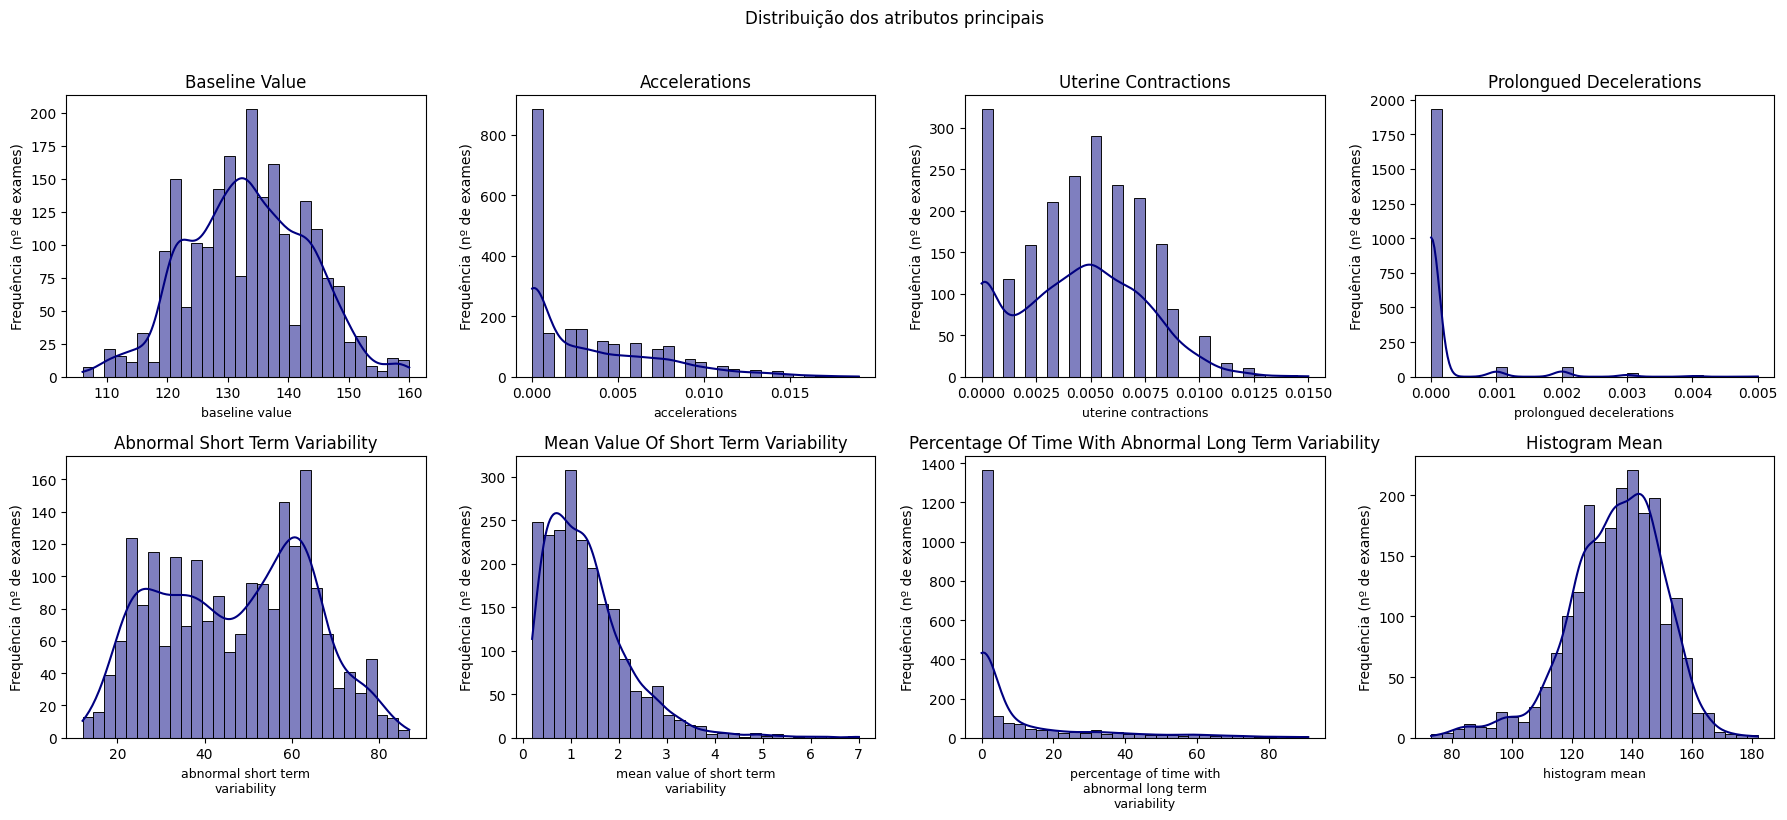

                                                     count     mean     std  \
baseline_value                                      2113.0  133.305   9.837   
accelerations                                       2113.0    0.003   0.004   
uterine_contractions                                2113.0    0.004   0.003   
prolongued_decelerations                            2113.0    0.000   0.001   
abnormal_short_term_variability                     2113.0   46.994  17.178   
mean_value_of_short_term_variability                2113.0    1.335   0.884   
percentage_of_time_with_abnormal_long_term_vari...  2113.0    9.795  18.337   
histogram_mean                                      2113.0  134.600  15.610   

                                                      min      25%      50%  \
baseline_value                                      106.0  126.000  133.000   
accelerations                                         0.0    0.000    0.002   
uterine_contractions                               

In [7]:
principais = [
    "baseline_value", "accelerations", "uterine_contractions",
    "prolongued_decelerations", "abnormal_short_term_variability",
    "mean_value_of_short_term_variability",
    "percentage_of_time_with_abnormal_long_term_variability",
    "histogram_mean",
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), principais):
    sns.histplot(df[col], bins=30, kde=True, ax=ax, color="navy")
    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel(textwrap.fill(col.replace("_", " "), 28), fontsize=9)
    ax.set_ylabel("Frequência (nº de exames)")
fig.suptitle("Distribuição dos atributos principais", y=1.02)
plt.tight_layout()
plt.show()

print(df[principais].describe().T.round(3))

<h3>Interpretação dos Atributos Principais</h3>

<p style="text-align: justify;">
A variável <strong>baseline_value</strong> apresenta média de 133,3 bpm e mediana de 133 bpm, indicando uma distribuição relativamente simétrica. O desvio padrão de 9,84 bpm demonstra uma dispersão moderada dos valores em torno da média. Observa-se que 50% dos exames apresentam frequência cardíaca basal entre 126 e 140 bpm, faixa considerada predominante no conjunto de dados.
</p>

<p style="text-align: justify;">
O atributo <strong>accelerations</strong> possui média de 0,003 e mediana de 0,002, com forte concentração de valores próximos de zero. O histograma confirma uma distribuição altamente assimétrica à direita, indicando que acelerações mais elevadas são pouco frequentes. O valor máximo observado foi de 0,019, muito superior ao terceiro quartil (0,006), sugerindo a presença de valores extremos.
</p>

<p style="text-align: justify;">
A variável <strong>uterine_contractions</strong> apresenta média de 0,004 e mediana de 0,005. Apesar de também apresentar assimetria positiva, sua distribuição é menos concentrada em zero quando comparada às acelerações e desacelerações. Os valores concentram-se principalmente entre 0,002 e 0,007, correspondendo ao intervalo interquartil.
</p>

<p style="text-align: justify;">
Em <strong>prolongued_decelerations</strong>, tanto o primeiro quartil quanto a mediana e o terceiro quartil são iguais a zero. Esse resultado, juntamente com o histograma, demonstra que a grande maioria dos exames não apresenta desacelerações prolongadas. A média próxima de zero e o valor máximo de 0,005 evidenciam que tais eventos são raros na amostra.
</p>

<p style="text-align: justify;">
A variável <strong>abnormal_short_term_variability</strong> possui média de 46,99 e mediana de 49, indicando distribuição relativamente equilibrada. O intervalo entre os quartis (32 a 61) mostra uma dispersão considerável dos dados, enquanto o desvio padrão de 17,18 confirma a existência de variabilidade significativa entre os registros.
</p>

<p style="text-align: justify;">
O atributo <strong>mean_value_of_short_term_variability</strong> apresenta média de 1,34 e mediana de 1,2. A distribuição é claramente assimétrica à direita, com poucos registros alcançando o valor máximo de 7,0. A maior parte dos exames encontra-se entre 0,7 e 1,7, conforme indicado pelos quartis.
</p>

<p style="text-align: justify;">
A variável <strong>percentage_of_time_with_abnormal_long_term_variability</strong> apresenta uma das distribuições mais assimétricas do conjunto. Embora a média seja de 9,8%, tanto o primeiro quartil quanto a mediana são iguais a 0%, evidenciando que mais da metade dos exames não apresenta períodos de variabilidade anormal de longo prazo. O elevado desvio padrão de 18,34 e o valor máximo de 91% indicam a presença de alguns casos extremos.
</p>

<p style="text-align: justify;">
Por fim, o atributo <strong>histogram_mean</strong> apresenta média de 134,6 bpm e mediana de 136 bpm, valores bastante próximos. O histograma exibe formato aproximadamente normal, com distribuição concentrada entre 125 e 145 bpm. O desvio padrão de 15,61 bpm indica uma dispersão moderada, enquanto os valores mínimo (73 bpm) e máximo (182 bpm) sugerem a existência de alguns registros mais extremos

<h3>Correlação entre os atributos</h3>

<p align="justify"> Nesta etapa, será calculada a <strong>matriz de correlação de Pearson</strong> entre os 21 atributos e exibida em um mapa de calor (<em>heatmap</em>). O coeficiente de Pearson varia de -1 a 1 e mede o quanto dois atributos variam juntos de forma linear: valores próximos de 1 indicam que crescem juntos, próximos de -1 indicam que um cresce quando o outro diminui, e próximos de 0 indicam ausência de relação linear. Em seguida, serão listados os pares de atributos com correlação absoluta acima de 0,8. </p>

<p align="justify"> Essa análise é importante porque atributos muito correlacionados carregam informação redundante. Isso pode prejudicar modelos lineares (multicolinearidade), dificulta a interpretação da importância de cada atributo e justifica o uso de seleção de atributos ou redução de dimensionalidade, como o PCA. </p>

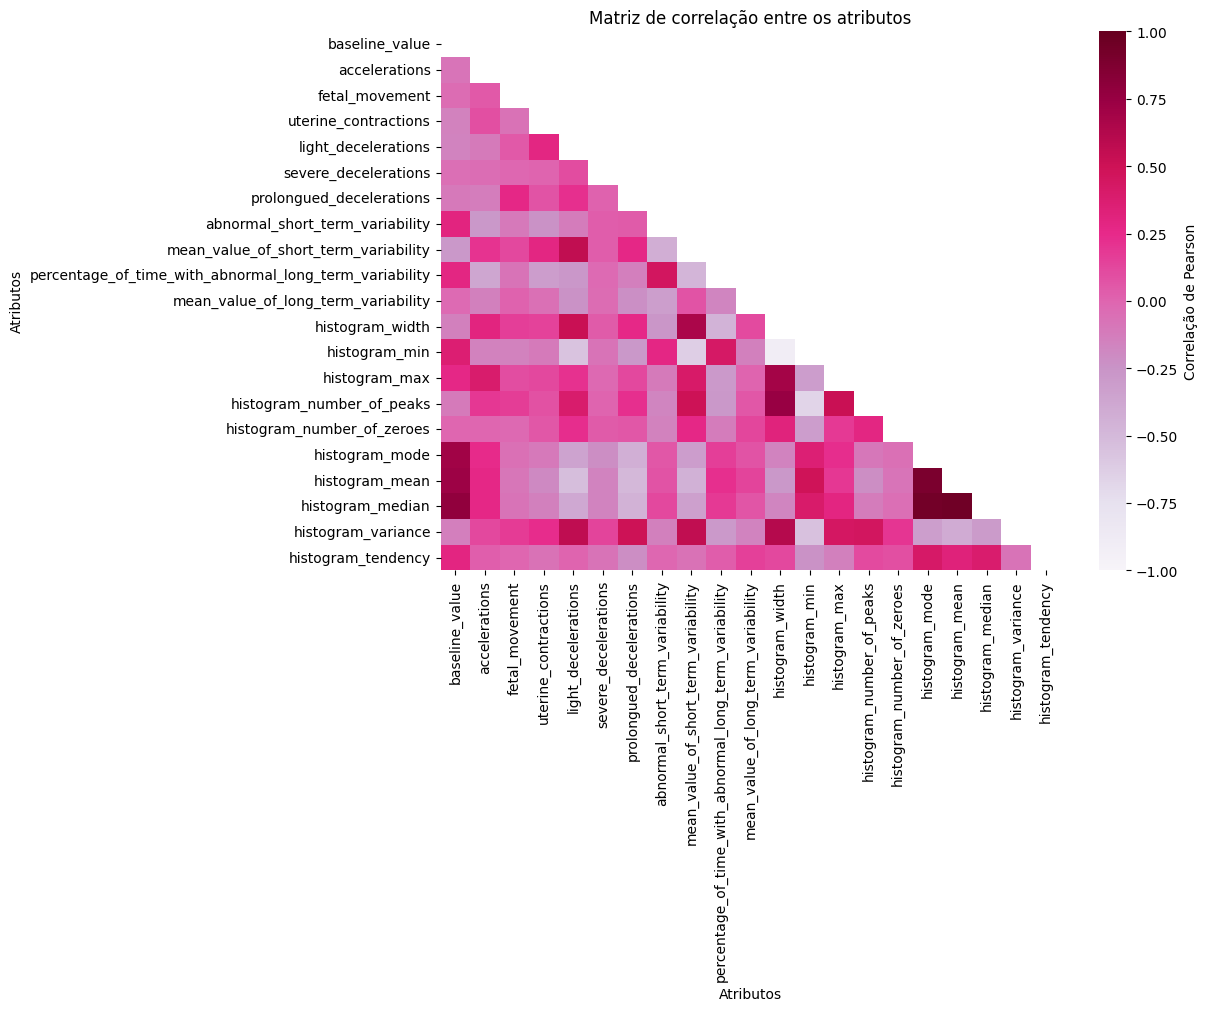

In [8]:
corr = df[atributos].corr()
mascara = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr,
    mask=mascara,
    cmap="PuRd",
    center=0,
    vmin=-1,
    vmax=1,
    annot=False,
    cbar_kws={"label": "Correlação de Pearson"}
)

plt.xlabel("Atributos")
plt.ylabel("Atributos")
plt.title("Matriz de correlação entre os atributos")
plt.show()



<div style="text-align: justify;">

<p>
A matriz de correlação permite avaliar a intensidade e a direção das relações lineares entre os atributos do conjunto de dados. As cores mais próximas do vinho indicam correlações positivas fortes, enquanto os tons de branco/rosa claro/rosa claro acinzentado representam correlações negativas fortes. Valores próximos do branco indicam correlação fraca ou inexistente entre as variáveis.
</p>

<p>
Observa-se uma forte correlação positiva entre <strong>histogram_mean</strong>, <strong>histogram_median</strong> e <strong>baseline_value</strong>. Esse resultado era esperado, pois todas essas variáveis descrevem medidas centrais da frequência cardíaca fetal. Dessa forma, quando a frequência cardíaca média aumenta, a mediana e o valor basal tendem a aumentar conjuntamente.
</p>

<p>
Também se destaca a elevada correlação positiva entre <strong>histogram_mean</strong> e <strong>histogram_median</strong>, indicando que ambas fornecem informações bastante semelhantes sobre a distribuição dos batimentos cardíacos. Essa forte associação sugere uma possível redundância de informação entre esses atributos.
</p>

<p>
As variáveis <strong>accelerations</strong> e <strong>mean_value_of_short_term_variability</strong> apresentam correlação positiva moderada. Isso sugere que fetos que apresentam maior número de acelerações tendem a exibir maior variabilidade de curto prazo, característica frequentemente associada a uma atividade cardíaca mais dinâmica.
</p>

<p>
Por outro lado, observa-se uma correlação negativa relevante entre <strong>abnormal_short_term_variability</strong> e <strong>mean_value_of_short_term_variability</strong>. Esse comportamento é coerente, uma vez que um aumento no percentual de variabilidade anormal tende a ocorrer simultaneamente à redução da variabilidade média considerada normal.
</p>

<p>
As variáveis relacionadas às desacelerações cardíacas, especialmente <strong>prolongued_decelerations</strong> e <strong>light_decelerations</strong>, apresentam correlações positivas com algumas medidas de variabilidade e características do histograma. Isso indica que eventos de desaceleração podem estar associados a alterações observáveis no padrão da frequência cardíaca fetal.
</p>

<p>
Outro padrão importante é a correlação negativa observada entre <strong>histogram_width</strong> e variáveis associadas à variabilidade anormal. Em geral, larguras maiores do histograma tendem a estar relacionadas a menores níveis de variabilidade considerada anormal, sugerindo um comportamento cardíaco mais estável.
</p>

<p>
As variáveis <strong>fetal_movement</strong> e <strong>uterine_contractions</strong> apresentam correlações relativamente fracas com a maioria dos demais atributos. Esse resultado indica que seus efeitos sobre as demais características do exame podem ser menos diretos ou depender de combinações com outros fatores fisiológicos.
</p>

<p>
De maneira geral, a matriz revela grupos de atributos altamente relacionados, especialmente aqueles derivados do histograma da frequência cardíaca fetal e das medidas de tendência central. A presença dessas correlações elevadas sugere que algumas variáveis podem fornecer informações semelhantes, o que deve ser considerado durante a seleção de atributos e a construção de modelos preditivos. Além disso, as correlações negativas observadas entre variáveis de variabilidade normal e anormal indicam relações fisiologicamente consistentes, reforçando a qualidade e a coerência dos dados analisados.
</p>

</div>

<h3>Associação dos atributos com o estado de saúde fetal</h3>

<p align="justify"> Nesta etapa, será calculada a <strong>correlação de Spearman</strong> entre cada atributo e a variável alvo <code>fetal_health</code>, e o resultado será exibido em um gráfico de barras horizontais, ordenado do valor mais negativo ao mais positivo. O coeficiente de Spearman varia de -1 a 1 e mede o quanto a relação entre duas variáveis segue uma <strong>ordem monotônica</strong>: ele é calculado sobre os <em>rankings</em> dos valores, e não sobre os valores em si. Valores positivos indicam que o atributo tende a aumentar quando a classe vai de normal para patológico, e valores negativos indicam o contrário. </p>

<p align="justify"> Foi escolhido o Spearman, e não o Pearson, porque vários atributos são assimétricos e concentram muitos valores em zero, e porque o alvo é ordinal (normal, suspeito, patológico). O Spearman é menos sensível a outliers e não exige relação linear. O objetivo é ter uma primeira indicação de quais atributos mais se associam ao estado fetal, o que ajuda a justificar a escolha dos atributos principais e a interpretar os modelos depois. Essa análise mede apenas associação com cada atributo isoladamente, sem considerar interações entre eles. </p>

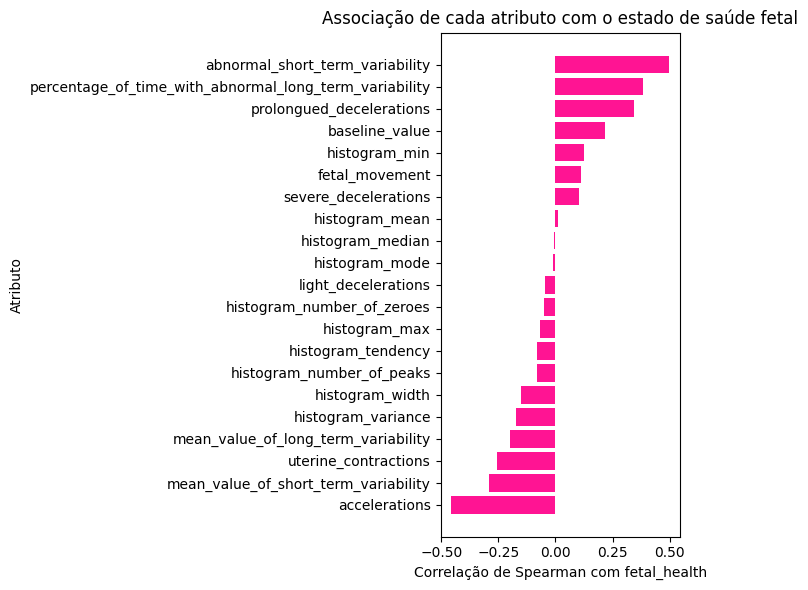

In [9]:
corr_alvo = (df.corr(method="spearman")["fetal_health"]
               .drop("fetal_health").sort_values())

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(corr_alvo.index, corr_alvo.values, color="deeppink")
ax.set_xlabel("Correlação de Spearman com fetal_health")
ax.set_ylabel("Atributo")
ax.set_title("Associação de cada atributo com o estado de saúde fetal")
plt.tight_layout()
plt.show()



<div style="text-align: justify;">

<p>
O gráfico apresenta a correlação de Spearman entre cada atributo e a variável <strong>fetal_health</strong>, permitindo identificar quais características possuem maior associação com o estado de saúde fetal. Correlações positivas indicam que valores mais elevados do atributo tendem a estar associados a classes de saúde fetal mais críticas, enquanto correlações negativas sugerem associação com condições mais saudáveis.
</p>

<p>
Observa-se que o atributo <strong>abnormal_short_term_variability</strong> apresenta a maior correlação positiva com o estado de saúde fetal, aproximadamente 0,5. Esse resultado indica que aumentos na variabilidade anormal de curto prazo estão fortemente associados a piores condições fetais, tornando essa variável uma das mais relevantes para a classificação do estado de saúde.
</p>

<p>
Também se destacam as variáveis <strong>percentage_of_time_with_abnormal_long_term_variability</strong> e <strong>prolongued_decelerations</strong>, que apresentam correlações positivas moderadas. Esses resultados sugerem que uma maior proporção de períodos com variabilidade anormal de longo prazo e a ocorrência de desacelerações prolongadas estão relacionadas a quadros fetais potencialmente mais preocupantes.
</p>

<p>
As variáveis <strong>baseline_value</strong>, <strong>histogram_min</strong>, <strong>fetal_movement</strong> e <strong>severe_decelerations</strong> exibem correlações positivas mais fracas, mas ainda perceptíveis. Embora contribuam para a caracterização do estado fetal, sua influência individual parece ser menor quando comparada aos atributos mais fortemente correlacionados.
</p>

<p>
Por outro lado, algumas variáveis apresentam correlação negativa com <strong>fetal_health</strong>. Entre elas, destaca-se <strong>accelerations</strong>, que possui a correlação negativa mais intensa, próxima de -0,45. Esse comportamento sugere que maiores níveis de aceleração da frequência cardíaca fetal tendem a estar associados a melhores condições de saúde, sendo um importante indicativo de vitalidade fetal.
</p>

<p>
As variáveis <strong>mean_value_of_short_term_variability</strong>, <strong>uterine_contractions</strong>, <strong>mean_value_of_long_term_variability</strong> e <strong>histogram_variance</strong> também apresentam correlações negativas moderadas. Esses resultados indicam que valores mais elevados dessas características costumam estar associados a condições fetais mais favoráveis.
</p>

<p>
Observa-se ainda que atributos como <strong>histogram_mean</strong>, <strong>histogram_median</strong> e <strong>histogram_mode</strong> apresentam correlações muito próximas de zero. Isso sugere que, individualmente, essas variáveis possuem baixa capacidade de discriminar os diferentes estados de saúde fetal, embora possam contribuir quando utilizadas em conjunto com outros atributos em modelos preditivos.
</p>

<p>
De maneira geral, os resultados indicam que as medidas relacionadas à variabilidade da frequência cardíaca fetal e às desacelerações são os fatores mais relevantes para a avaliação do estado de saúde fetal. Em contraste, medidas centrais do histograma apresentam menor associação direta. Essas evidências sugerem que variáveis ligadas à dinâmica e à variabilidade dos batimentos cardíacos possuem maior potencial explicativo e preditivo para a identificação de alterações no bem-estar fetal.
</p>

</div>

<h3>Comparação dos atributos entre as classes</h3>

<p align="justify"> Nesta etapa, os atributos serão comparados entre as três classes de saúde fetal (normal, suspeito e patológico) por meio de <strong>boxplots</strong>. Cada boxplot resume a distribuição de um atributo em cada classe: a linha central é a mediana, a caixa vai do primeiro ao terceiro quartil (os 50% centrais dos exames), os "bigodes" indicam a faixa de valores sem outliers e os pontos isolados são valores atípicos. Foram escolhidos seis atributos de relevância clínica, entre eles medidas de variabilidade e a frequência basal. Também será impressa a <strong>mediana de cada atributo por classe</strong>, para dar números concretos à comparação visual. </p>

<p align="justify"> O objetivo é verificar quais atributos separam melhor as classes. Se as caixas de duas classes estiverem bem afastadas, o atributo tem potencial para distingui-las. Se estiverem muito sobrepostas, ele ajuda pouco sozinho. Essa comparação também antecipa quais classes devem ser mais difíceis de separar nos modelos. Por fim, o atributo <code>prolongued_decelerations</code> fica de fora dos boxplots porque é igual a zero na grande maioria dos exames, o que deixaria o gráfico pouco informativo. Para ele, compara-se a <strong>proporção de exames com valor maior que zero</strong> em cada classe. </p>

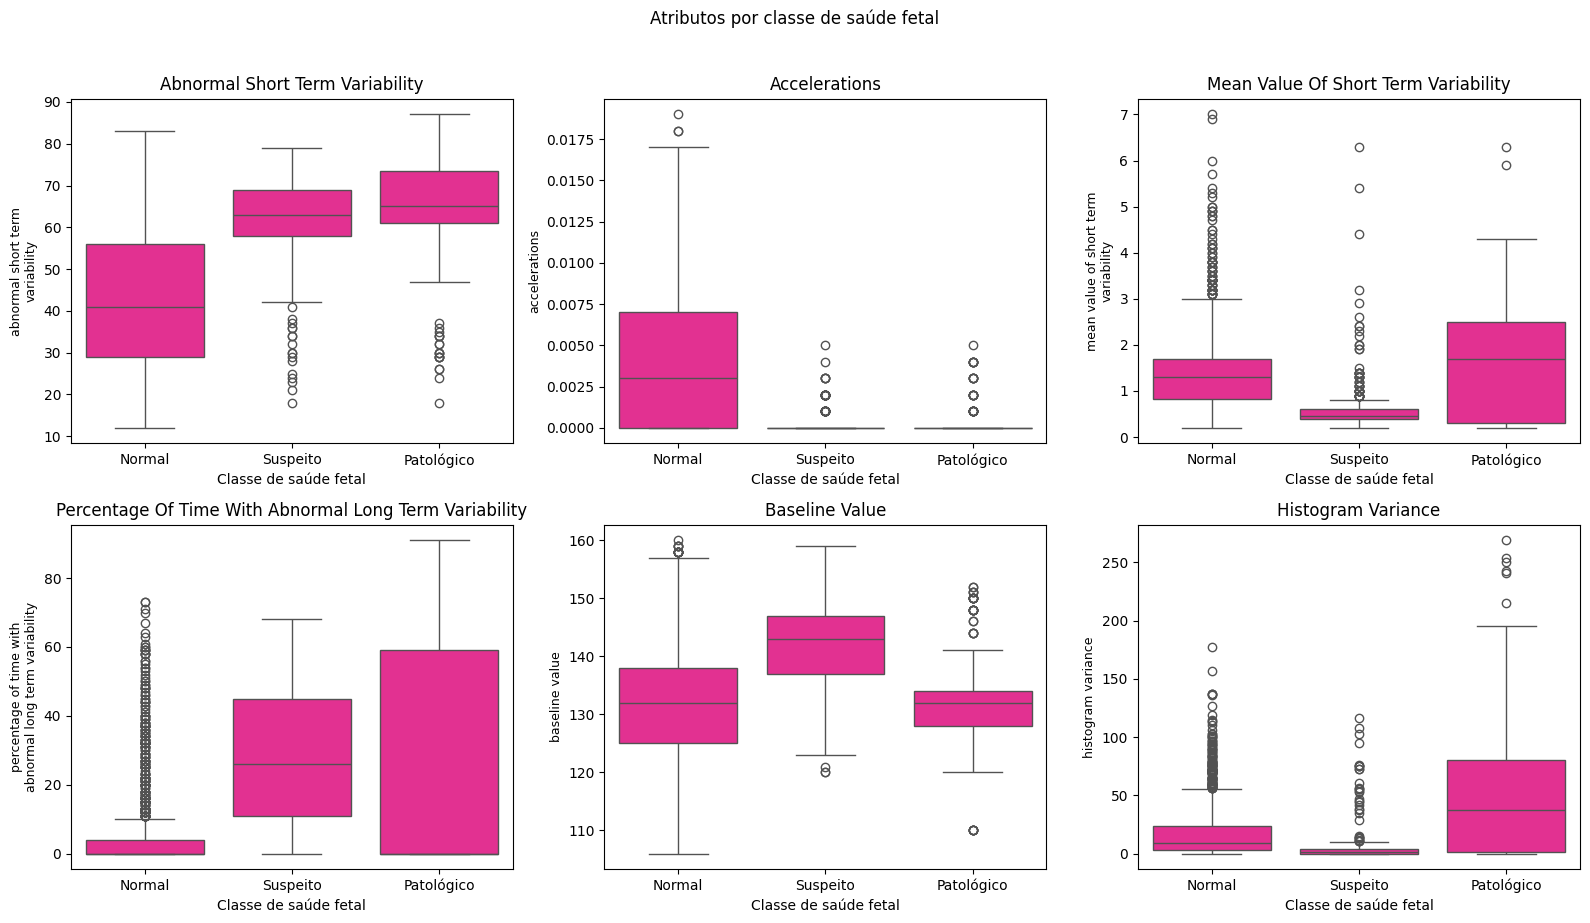

In [10]:
eda = df.assign(classe=df["fetal_health"].map(nomes_classes))

comparar = [
    "abnormal_short_term_variability", "accelerations",
    "mean_value_of_short_term_variability",
    "percentage_of_time_with_abnormal_long_term_variability",
    "baseline_value", "histogram_variance",
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), comparar):
    sns.boxplot(data=eda, x="classe", y=col, order=ordem, ax=ax, color="deeppink")
    ax.set_title(col.replace("_", " ").title())  
    ax.set_xlabel("Classe de saúde fetal")
    ax.set_ylabel(textwrap.fill(col.replace("_", " "), 30), fontsize=9)
fig.suptitle("Atributos por classe de saúde fetal", y=1.02)
plt.tight_layout()
plt.show()





<div style="text-align: justify;">

<p>
Os boxplots evidenciam diferenças importantes entre as classes de saúde fetal (Normal, Suspeito e Patológico), confirmando os resultados observados na análise de correlação. De maneira geral, os atributos relacionados à variabilidade da frequência cardíaca fetal e às desacelerações apresentam maior capacidade de distinguir as diferentes condições clínicas dos fetos.
</p>

<p>
O atributo <strong>abnormal_short_term_variability</strong> apresenta aumento progressivo entre as classes. A mediana cresce de aproximadamente 41 para a classe Normal, para 63 na classe Suspeito e 65 na classe Patológico. Esse comportamento confirma a correlação positiva observada anteriormente e indica que níveis elevados de variabilidade anormal de curto prazo estão associados a piores condições fetais.
</p>

<p>
O atributo <strong>accelerations</strong> apresenta comportamento oposto. A mediana é aproximadamente 0,003 na classe Normal, enquanto nas classes Suspeito e Patológico o valor é praticamente zero. Esse resultado explica a forte correlação negativa observada com o estado de saúde fetal e sugere que a presença de acelerações está associada a fetos com melhores condições clínicas.
</p>

<p>
A variável <strong>mean_value_of_short_term_variability</strong> apresenta um comportamento interessante. A classe Suspeito possui os menores valores médios, com mediana em torno de 0,45, enquanto as classes Normal e Patológico apresentam medianas mais elevadas, próximas de 1,30 e 1,70, respectivamente. Esse padrão indica que a relação entre esse atributo e a saúde fetal não é estritamente linear, sugerindo interações mais complexas com outros indicadores fisiológicos.
</p>

<p>
A variável <strong>percentage_of_time_with_abnormal_long_term_variability</strong> apresenta forte separação entre as classes. A mediana é próxima de zero para a classe Normal, aumenta para cerca de 26% na classe Suspeito e volta a apresentar grande dispersão na classe Patológico. Esse resultado demonstra que períodos prolongados de variabilidade anormal constituem um importante sinal de comprometimento fetal.
</p>

<p>
O atributo <strong>baseline_value</strong> apresenta diferenças moderadas entre os grupos. A classe Suspeito exibe os maiores valores centrais, com mediana próxima de 143 bpm, enquanto as classes Normal e Patológico apresentam valores semelhantes, próximos de 132 bpm. Isso sugere que alterações na frequência cardíaca basal podem estar associadas principalmente à transição entre condições normais e suspeitas.
</p>

<p>
A variável <strong>histogram_variance</strong> mostra uma das diferenças mais marcantes. A mediana cresce de aproximadamente 9 na classe Normal para 37 na classe Patológico, enquanto a classe Suspeito apresenta valores bastante baixos, próximos de 1. Além disso, observa-se elevada dispersão na classe Patológico, indicando grande heterogeneidade nos padrões da frequência cardíaca desses fetos.
</p>

<p>
As <strong>desacelerações prolongadas</strong> constituem outro indicador relevante. Apenas cerca de 4,2% dos exames normais apresentam desacelerações prolongadas,  percentual significativamente menor do que o observado nas categorias suspeita e patológica. A distribuição desse atributo evidencia uma relação entre a ocorrência de desacelerações prolongadas e a gravidade da condição fetal, indicando que alterações persistentes na frequência cardíaca fetal são mais comuns em casos associados a risco clínico elevado. Dessa forma, essa variável mostra potencial discriminatório para a classificação do estado de saúde fetal.

<h2>Split treino/teste</h2>
<p style="text-align: justify;""> A divisão do dataset entre conjuntos de treinamento e teste é fundamental para avaliar a capacidade de generalização do modelo, ou seja, seu desempenho em dados novos e não observados durante o treinamento. O conjunto de treinamento é utilizado para o aprendizado do modelo, enquanto o conjunto de teste permite avaliar seu desempenho de forma mais realista [2]. Neste trabalho, foram reservados 20% dos dados para teste e 80% dos dados para treino.<br>
 A divisão é <strong>estratificada</strong> pelo alvo, de modo que as proporções de exames normais, suspeitos e patológicos sejam mantidas nos dois conjuntos, o que é importante porque a classe patológica é rara. O conjunto de teste fica reservado e só será usado <strong>uma única vez</strong>, ao final do trabalho, para avaliar o modelo escolhido. Toda a comparação entre modelos e a otimização de hiperparâmetros usam apenas o conjunto de treino, por meio de validação cruzada, evitando <strong>vazamento de dados</strong>. </p>

Realizando o split de treino e teste e verificando a distribuição dos dados em cada um

In [11]:

TAMANHO_TESTE = 0.2
semente_aleatoria = 42

indices = df.index
indices_treino, indices_teste = train_test_split(
    indices, test_size=TAMANHO_TESTE, random_state=semente_aleatoria, stratify=df["fetal_health"]
)

df_treino = df.loc[indices_treino]
df_teste = df.loc[indices_teste]

print("Treino:", df_treino.shape, "| Teste:", df_teste.shape)
print("\nProporção das classes no treino:")
print(df_treino["fetal_health"].value_counts(normalize=True).sort_index().round(3))
print("\nProporção das classes no teste:")
print(df_teste["fetal_health"].value_counts(normalize=True).sort_index().round(3))


X_treino = df_treino[atributos]
y_treino = df_treino["fetal_health"]
X_teste = df_teste[atributos]
y_teste = df_teste["fetal_health"]

Treino: (1690, 22) | Teste: (423, 22)

Proporção das classes no treino:
fetal_health
1    0.779
2    0.138
3    0.083
Name: proportion, dtype: float64

Proporção das classes no teste:
fetal_health
1    0.780
2    0.137
3    0.083
Name: proportion, dtype: float64


<p align="justify"> A divisão resultou em 1690 exames de treino e 423 de teste. As proporções das classes são semelhantes nos dois conjuntos (treino: 77,9% normal, 13,8% suspeito, 8,3% patológico; teste: 78% normal, 13,7% suspeito, 8,3% patológico), o que confirma que a estratificação funcionou. </p>

<h2>Métricas de avaliação</h2>

<p align="justify"> Como as classes são desbalanceadas, a acurácia não é suficiente: um modelo que sempre prevê "normal" acertaria cerca de 78% dos exames sem identificar nenhum caso de risco. Por isso serão usadas as seguintes métricas: </p>

<ul>
    <li><b>F1-macro</b>: média do F1 (equilíbrio entre precisão e recall) calculado em cada classe, dando o mesmo peso a todas, inclusive às raras.</li>
    <li><b>Balanced accuracy</b>: média do recall de cada classe. Um classificador que sempre prevê a classe majoritária obtém 1/3 nessa métrica.</li>
    <li><b>Recall da classe patológica</b>: proporção de exames patológicos corretamente identificados. É a métrica mais relevante clinicamente, pois classificar um caso patológico como normal é o erro mais grave.</li>
    <li><b>Matriz de confusão</b>: mostra, para cada classe real, como os exames foram classificados, revelando onde estão os erros.</li>
</ul>

<p align="justify"> A acurácia também será registrada, apenas para evidenciar como ela pode ser muito enganosa neste problema. A avaliação é feita por <strong>validação cruzada estratificada de 5 folds</strong> sobre o conjunto de treino, com a mesma divisão de folds para todos os modelos, para que a comparação seja justa. </p>

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=semente_aleatoria)

scoring = {
    "acuracia": "accuracy",
    "f1_macro": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
    "recall_patologico": make_scorer(recall_score, labels=[3], average="macro", zero_division=0),
}

<h3>Modelo base 1: Baseline(classe mais frequente)</h3>

<p align="justify"> O primeiro modelo de referência é o <code>DummyClassifier</code>, que ignora os atributos e sempre prevê a classe mais frequente (normal). Ele mostra o desempenho de um modelo que não aprende nada: qualquer modelo útil precisa superá-lo, principalmente nas métricas que não dependem da proporção das classes, como o F1-macro e a balanced accuracy. </p>

In [13]:
baseline = DummyClassifier(strategy="most_frequent")

    
y_previsto_baseline = cross_val_predict(baseline, X_treino, y_treino, cv=cv)

acuracia_baseline = accuracy_score(y_treino, y_previsto_baseline)
f1_baseline = f1_score(y_treino, y_previsto_baseline, average="macro", zero_division=0)
balanced_baseline = balanced_accuracy_score(y_treino, y_previsto_baseline)
recall_patologico_baseline = recall_score(y_treino, y_previsto_baseline, labels=[3],
                                          average="macro", zero_division=0)

print(f"Acurácia do baseline: {acuracia_baseline:.3f}")
print(f"F1-macro do baseline: {f1_baseline:.3f}")
print(f"Balanced accuracy do baseline: {balanced_baseline:.3f}")
print(f"Recall da classe patológica do baseline: {recall_patologico_baseline:.3f}")

Acurácia do baseline: 0.779
F1-macro do baseline: 0.292
Balanced accuracy do baseline: 0.333
Recall da classe patológica do baseline: 0.000


<h3>Modelo base  2: regressão logística simples</h3>

<p align="justify"> O segundo modelo de referência é uma <strong>regressão logística simples</strong>, com hiperparâmetros padrão e normalização dos atributos (<code>StandardScaler</code>) dentro de um <code>Pipeline</code>, de modo que a normalização é ajustada apenas nos dados de treino de cada fold. Ele mostra o quanto um modelo linear básico, sem nenhum ajuste, já consegue extrair dos dados, e é o <strong>piso</strong> que os modelos otimizados precisam superar. </p>

In [14]:
regressão_logistica_simples = Pipeline([
    ("escala", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1000, random_state=semente_aleatoria)),
])

y_previsto_logistica = cross_val_predict(regressão_logistica_simples, X_treino, y_treino, cv=cv)

acuracia_logistica = accuracy_score(y_treino, y_previsto_logistica)
f1_logistica = f1_score(y_treino, y_previsto_logistica, average="macro", zero_division=0)
balanced_logistica = balanced_accuracy_score(y_treino, y_previsto_logistica)
recall_patologico_logistica = recall_score(y_treino, y_previsto_logistica, labels=[3],
                                           average="macro", zero_division=0)

print(f"Acurácia da regressão logística: {acuracia_logistica:.3f}")
print(f"F1-macro da regressão logística: {f1_logistica:.3f}")
print(f"Balanced accuracy da regressão logística: {balanced_logistica:.3f}")
print(f"Recall da classe patológica da regressão logística: {recall_patologico_logistica:.3f}")

Acurácia da regressão logística: 0.888
F1-macro da regressão logística: 0.781
Balanced accuracy da regressão logística: 0.770
Recall da classe patológica da regressão logística: 0.714


<h3>Matrizes de confusão dos modelos base</h3>

<p align="justify"> Para ver onde cada modelo base erra, foram geradas as matrizes de confusão a partir de previsões obtidas por validação cruzada no conjunto de treino.  </p>

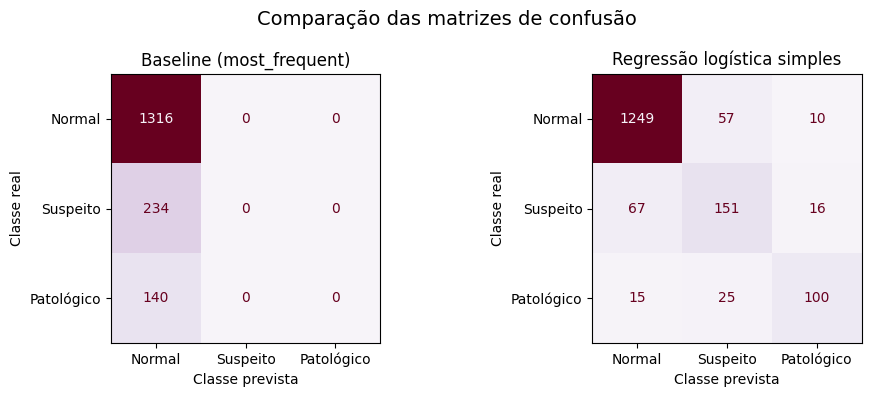

In [15]:
matriz_confusao_baseline = confusion_matrix(y_treino, y_previsto_baseline, labels=[1, 2, 3])
matriz_confusao_regressao = confusion_matrix(y_treino, y_previsto_logistica, labels=[1, 2, 3])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay(
    matriz_confusao_baseline,
    display_labels=ordem
).plot(cmap="PuRd", ax=axes[0], colorbar=False)

axes[0].set_xlabel("Classe prevista")
axes[0].set_ylabel("Classe real")
axes[0].set_title("Baseline (most_frequent)")
axes[0].grid(False)

ConfusionMatrixDisplay(
    matriz_confusao_regressao,
    display_labels=ordem
).plot(cmap="PuRd", ax=axes[1], colorbar=False)

axes[1].set_xlabel("Classe prevista")
axes[1].set_ylabel("Classe real")
axes[1].set_title("Regressão logística simples")
axes[1].grid(False)

fig.suptitle("Comparação das matrizes de confusão", fontsize=14)
plt.tight_layout()
plt.show()

In [16]:
piso = {
    "Acurácia": acuracia_logistica,
    "F1 Macro": f1_logistica,
    "Balanced Accuracy": balanced_logistica,
    "Recall Patológico": recall_patologico_logistica
}

print("Piso (regressão logística simples, CV no treino):")
for metrica, valor in piso.items():
    print(f"{metrica}: {valor:.4f}")

Piso (regressão logística simples, CV no treino):
Acurácia: 0.8876
F1 Macro: 0.7808
Balanced Accuracy: 0.7696
Recall Patológico: 0.7143


<h3>Resultado dos modelos base</h3>

<p align="justify"> O <code>DummyClassifier</code> obteve acurácia de  0.779, mas F1-macro de apenas  0.292, balanced accuracy de 0.333 e recall da classe patológica de 0%. Isso confirma que a acurácia é enganosa neste problema, pois o modelo acerta quase todos os exames normais sem identificar nenhum caso de risco, o que é extremamente preocupante no contezto médico, visto que nesses contextos o falso negativo deve ser minimizado. A regressão logística simples obteve acuracia 0.888, F1-macro de 0.779, balanced accuracy de 0.769 e recall patológico de  0.714, desempenho bem superior ao do Dummy.<br>
    As matrizes de confusão mostram que o modelo Dummy previu todos os exemplos como Normal, acertando apenas a classe majoritária e falhando em identificar casos Suspeitos e Patológicos( o que já é esperado desse modelo). Já a regressão logística apresentou desempenho muito melhor, acertando a maior parte das três classes. Os melhores resultados ocorreram para a classe Normal, enquanto a classe Suspeito foi a mais difícil de classificar. A maioria dos erros ocorreu entre classes vizinhas (Normal e Suspeito, ou Suspeito e Patológico), indicando que o modelo consegue distinguir razoavelmente bem os casos mais extremos, mas falha em distinguir casos com valores mais próximos. </p>

<p align="justify"> O <strong>piso a ser superado</strong> é, portanto, acuracia= 0.888,  F1-macro = 0.779, balanced accuracy =  0.769 e recall patológico = 0.714, referentes à regressão logística simples. Os modelos otimizados com o Optuna devem superar esses valores para justificar sua complexidade. </p>

<h2>Algoritmos e pipelines comparados</h2>

<p align="justify"> Serão comparados cinco algoritmos, além do baseline, de famílias diferentes: <strong>regressão logística</strong> (modelo linear), <strong>k-NN</strong> (baseado em distância), <strong>SVM</strong> (margem máxima, com kernels não lineares), <strong>Random Forest</strong> (conjunto de árvores independentes) e <strong>Gradient Boosting</strong> (árvores treinadas em sequência, cada uma corrigindo os erros das anteriores). Para o Gradient Boosting foi usado o <code>HistGradientBoostingClassifier</code> do scikit-learn, uma implementação baseada em histogramas, mais rápida e que aceita pesos de classe. </p>

<p align="justify"> Cada algoritmo é um <code>Pipeline</code> com até três etapas: normalização (quando necessária), redução de dimensionalidade ou seleção de atributos, e o classificador. Todas as escolhas, inclusive as de pré-processamento, são hiperparâmetros otimizados pelo Optuna, com <strong>100 tentativas por algoritmo</strong>. </p>


Armazenando o númeor de atributos, a quantidade de tentativas, os algoritmos e os algoritmos impactados pela escala

In [17]:
NUM_ATRIBUTOS = len(atributos)   
NUM_TENTATIVAS = 100
ALGORITMOS = ["regressao_logistica", "knn", "svm", "floresta_aleatoria", "gradient_boosting"]
ALGORITMOS_COM_ESCALA = ["regressao_logistica", "knn", "svm"]

<h3>Normalização dos atributos</h3>

<p align="justify"> Os atributos têm escalas muito diferentes (por exemplo, <code>baseline_value</code> na casa das centenas e <code>severe_decelerations</code> próximo de zero). A regressão logística, o k-NN e a SVM são sensíveis à escala, por dependerem de distâncias, produtos escalares ou regularização, e por isso <strong>terão que sofrer normalização</strong>. Random Forest e Gradient Boosting dividem os dados por limiares em um atributo de cada vez, então a escala não altera as divisões e <strong>não recebem normalização</strong>. O tipo de normalizador (<code>StandardScaler</code>, <code>RobustScaler</code> ou <code>MinMaxScaler</code>) é um hiperparâmetro, pois vários atributos têm outliers e muitos zeros. O normalizador fica dentro do <code>Pipeline</code>, sendo ajustado apenas no treino de cada fold, o que evita vazamento de dados. </p>

Abaixo é criada uma função onde o optuna irá sortear o tipo de normalizador e a função retona o objeto correspondente

In [18]:
def cria_normalizador(trial):
    nome = trial.suggest_categorical("normalizador", ["standard", "robust", "minmax"])
    normalizadores = {
        "standard": StandardScaler(),
        "robust": RobustScaler(),
        "minmax": MinMaxScaler(),
    }
    return normalizadores[nome]

<h3>Tratamento de <code>histogram_tendency</code></h3>

<p align="justify"> O atributo <code>histogram_tendency</code> assume três valores (-1, 0 e 1), correspondentes a histograma assimétrico à esquerda, simétrico e assimétrico à direita. Como esses valores têm uma <strong>ordem natural</strong> e já estão codificados numericamente, o atributo foi mantido como numérico, sem <em>one-hot encoding</em>. Isso evita criar colunas extras e preserva a informação de ordem. Para árvores, a codificação numérica não traz problema. Para regressão logística, k-NN e SVM, ela assume distâncias uniformes entre as categorias, uma simplificação aceitável com apenas três valores. Como todos os demais atributos são numéricos, não há outras etapas de codificação. é possiível oservar a distribuição dos dados no gráfico abaixo </p>

verificando quantos exames tem em cada valor de atributo

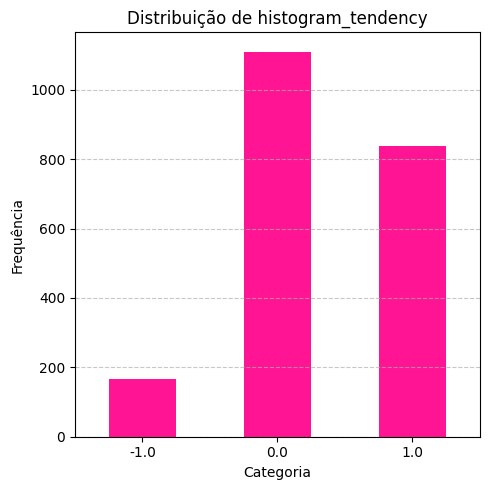

In [19]:


contagem = df["histogram_tendency"].value_counts().sort_index()

ax = contagem.plot(
    kind="bar",
    figsize=(5,5),
    color="deeppink",
   
)

plt.title("Distribuição de histogram_tendency")
plt.xlabel("Categoria")
plt.ylabel("Frequência")
plt.xticks(rotation=0)



plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

In [20]:
print(df["histogram_tendency"].value_counts().sort_index())

histogram_tendency
-1.0     165
 0.0    1110
 1.0     838
Name: count, dtype: int64


O gráfico mostra que a categoria 0 é a mais frequente, seguida pela categoria 1, enquanto a categoria -1 aparece em quantidade significativamente menor. Isso indica um desbalanceamento entre as classes, com predominância de tendências neutras e positivas. Essa característica deve ser considerada na modelagem, pois pode influenciar o desempenho dos algoritmos em favor das classes mais representadas.

<h3>Desbalanceamento: peso das classes</h3>

<p align="justify"> Para lidar com o desbalanceamento, o parâmetro <code>class_weight</code> entra na busca do Optuna para os algoritmos que o suportam (regressão logística, SVM, Random Forest e Gradient Boosting), com as opções sem peso e <code>"balanced"</code>, que atribui a cada classe um peso inversamente proporcional à sua frequência. No Random Forest também é testado <code>"balanced_subsample"</code>, que recalcula os pesos em cada amostra <em>bootstrap</em>. O <strong>k-NN não possui esse parâmetro</strong>. Nele, o hiperparâmetro <code>weights</code> pondera os <em>vizinhos</em> pela distância, não as classes. Além disso, o Optuna maximiza o <strong>F1-macro</strong>, que dá o mesmo peso a todas as classes e penaliza modelos que ignoram as raras. </p>

<h3>Seleção de atributos e redução de dimensionalidade</h3>

<p align="justify"> A análise exploratória mostrou forte redundância entre atributos do histograma, como <code>histogram_mean</code>, <code>histogram_median</code> e <code>histogram_mode</code> (r entre 0,89 e 0,95) e o par <code>histogram_min</code> e <code>histogram_width</code> (r = −0,90). Isso justifica testar estratégias que reduzam a dimensionalidade. Em todos os pipelines, o Optuna escolhe entre: (i) <strong>nenhuma redução</strong>; (ii) <strong>seleção de atributos por RFE</strong> (<em>recursive feature elimination</em>), que remove a cada iteração os atributos menos importantes segundo um estimador guia, com o número de atributos mantidos (de 5 a 20) como hiperparâmetro; ou (iii) <strong>PCA</strong>, com o número de componentes (de 5 a 21) como hiperparâmetro, oferecido apenas aos modelos que usam normalização, pois o PCA é sensível à escala. O estimador guia do RFE é uma regressão logística nos modelos com normalização e um Random Forest pequeno (50 árvores) nos modelos de árvore, pois o RFE exige um estimador que atribua importância aos atributos e não funciona com o k-NN. Como as duas etapas ficam dentro do <code>Pipeline</code>, são ajustadas apenas no treino de cada fold, evitando o vazamento de dados por seleção de atributos. </p>

In [21]:
def cria_reducao(trial, algoritmo):
    opcoes = ["nenhuma", "rfe"] + (["pca"] if algoritmo in ALGORITMOS_COM_ESCALA else [])
    reducao = trial.suggest_categorical("reducao", opcoes)

    if reducao == "pca":
        return [PCA(n_components=trial.suggest_int("num_componentes", 5, NUM_ATRIBUTOS),
                    random_state=semente_aleatoria)]

    if reducao == "rfe":
        if algoritmo in ALGORITMOS_COM_ESCALA:
            guia = LogisticRegression(max_iter=2000, random_state=semente_aleatoria)
        else:
            guia = RandomForestClassifier(n_estimators=50, max_depth=8, n_jobs=-1,
                                          random_state=semente_aleatoria)
        return [RFE(guia,
                    n_features_to_select=trial.suggest_int("num_atributos_rfe", 5, NUM_ATRIBUTOS - 1),
                    step=2)]

    return []   

<h3>Otimização de hiperparâmetros com Optuna</h3>

<p align="justify"> A otimização é feita com o <strong>Optuna</strong>, usando o amostrador padrão TPE (<em>Tree-structure Parzen Estimator</em>), que explora o espaço de busca de forma bayesiana, concentrando as tentativas nas regiões mais promissoras. Foi ativada a opção <code>multivariate=True</code>, que considera a dependência entre hiperparâmetros. A função objetivo calcula o <strong>F1-macro médio de uma validação cruzada estratificada de 5 folds</strong> no conjunto de treino, e o Optuna busca maximizá-lo. Hiperparâmetros que variam em mais de uma ordem de grandeza (como <code>C</code> e a taxa de aprendizado) são sorteados em <strong>escala logarítmica</strong>, para evitar o viés de amostragem. Em cada estudo, a primeira tentativa é a configuração padrão do scikit-learn, o que permite verificar se a busca superou o modelo sem ajuste. Os estudos são salvos em arquivos <code>.db</code>, para não precisar repetir a otimização. O conjunto de teste não participa de nenhuma etapa da busca. </p>

<h3>O que é a regressão logística</h3>
A regressão logística, como a regressão linear, é um tipo de modelo linear que examina a relação entre variáveis independentes e uma variável-alvo. A principal diferença é que a regressão linear é usada quando a saída é um valor contínuo, por exemplo, prevendo a pontuação de crédito de alguém. A regressão logística é usada quando o resultado é categórico, como se um empréstimo é aprovado ou não.
<br>
Na regressão logística, o modelo prevê a probabilidade de ocorrência de um resultado específico
<h3>Espaço de busca: regressão logística</h3>
<table>
<tr><th>Hiperparâmetro</th><th>Intervalo</th><th>Justificativa</th></tr>
<tr><td>normalizador</td><td>standard, robust, minmax</td><td>atributos em escalas diferentes, com outliers e muitos zeros</td></tr>
<tr><td>redução</td><td>nenhuma, RFE (5–20 atributos), PCA (5–21 componentes)</td><td>redundância entre atributos do histograma</td></tr>
<tr><td><code>C</code></td><td>10⁻³ a 10² (escala log)</td><td>inverso da força de regularização, com efeito multiplicativo; cobre de regularização forte (útil com atributos correlacionados) a fraca</td></tr>
<tr><td><code>l1_ratio</code></td><td>0 ou 1</td><td>define o tipo de regularização: 0 equivale à penalização l2, que encolhe todos os coeficientes, e 1 equivale à l1, que zera alguns coeficientes e funciona como seleção de atributos embutida</td></tr>
<tr><td><code>class_weight</code></td><td>nenhum, balanced</td><td>desbalanceamento das classes</td></tr>
</table>
<p align="justify"> Fixos: <code>solver="saga"</code>, que suporta as regularizações l1 e l2 em problemas multiclasse, e <code>max_iter=5000</code>, para garantir convergência. O tipo de regularização é controlado por <code>l1_ratio</code>, e não por <code>penalty</code>, parâmetro descontinuado a partir da versão 1.8 do scikit-learn. </p>

<h4>Por que esses hiperparâmetros?</h4>
<p align="justify"> A regressão logística aprende um coeficiente para cada atributo e aplica uma <strong>penalização</strong> que impede esses coeficientes de crescerem demais. Como este conjunto tem atributos em escalas muito diferentes, muitos valores iguais a zero, outliers e forte redundância entre medidas do histograma, os hiperparâmetros escolhidos atuam justamente nesses pontos. </p>

<p align="justify"> Os hiperparâmetros atuam nos problemas do conjunto de dados: atributos em escalas diferentes, outliers, forte redundância e desbalanceamento das classes. </p>

<ul>
<li align="justify"><b>Normalizador:</b> a penalização trata todos os coeficientes igualmente, então atributos em escalas diferentes seriam penalizados de forma desigual. Os três tipos foram testados porque reagem de modo distinto aos outliers (o <code>RobustScaler</code> é o menos sensível).</li>
<li align="justify"><b>Redução:</b> atributos muito correlacionados (como <code>histogram_mean</code>, <code>histogram_median</code> e <code>histogram_mode</code>) tornam os coeficientes instáveis. O RFE descarta os menos úteis e o PCA os combina em componentes não correlacionados.</li>
<li align="justify"><b><code>C</code>:</b> controla a força da regularização (valores pequenos geram um modelo mais simples). A escala log dá a mesma atenção a cada ordem de grandeza, e o intervalo inclui o padrão (<code>C = 1</code>).</li>
<li align="justify"><b><code>l1_ratio</code>:</b> l2 (0) encolhe todos os coeficientes, e l1 (1) zera alguns, funcionando como seleção de atributos embutida. Foram testados só os extremos para manter a busca pequena.</li>
<li align="justify"><b><code>class_weight</code>:</b> com apenas 8,3% de patológicos, o modelo tende a favorecer a classe normal. O <code>"balanced"</code> faz errar um caso raro custar mais, o que tende a elevar o recall patológico.</li>
</ul>

<p align="justify"> O <code>saga</code> foi fixado por aceitar as penalizações l1 e l2 em problemas multiclasse, e <code>max_iter=5000</code> porque ele converge devagar em alguns casos (6 das 100 tentativas não convergiram). </p>

In [22]:
def cria_logistica(trial):
    parametros = {
        "C": trial.suggest_float("C", 1e-3, 1e2, log=True),
        "l1_ratio": trial.suggest_categorical("razao_l1", [0.0, 1.0]),
        "class_weight": trial.suggest_categorical("peso_classes", [None, "balanced"]),
        "solver": "saga",
        "max_iter": 5000,
        "random_state": semente_aleatoria,
    }
    return LogisticRegression(**parametros)

<h3>O que é o algoritmo k-nn</h3>
O algoritmo k-nearest neighbors (KNN), ou k vizinhos mais próximos, é um classificador de aprendizado supervisionado não paramétrico, que usa a proximidade para fazer classificações ou previsões sobre o agrupamento de um determinado ponto de dados.
<h3>Espaço de busca: k-NN</h3>
<table>
<tr><th>Hiperparâmetro</th><th>Intervalo</th><th>Justificativa</th></tr>
<tr><td>normalizador</td><td>standard, robust, minmax</td><td>o k-NN depende de distâncias</td></tr>
<tr><td>redução</td><td>nenhuma, RFE (5–20 atributos), PCA (5–21 componentes)</td><td>atributos redundantes pesam em dobro na distância; reduzir pode ajudar</td></tr>
<tr><td><code>n_neighbors</code></td><td>1 a 1320 (escala log)</td><td>k pequeno gera fronteiras irregulares (alta variância), e k grande tende a classificar quase tudo como a classe majoritária (alto viés), o que prejudica as classes raras; a escala logarítmica é usada porque a faixa cobre mais de duas ordens de grandeza, e assim valores pequenos, onde o k-NN costuma funcionar melhor, são testados com a mesma densidade que valores grandes; o limite superior é imposto pelo número de exemplos de treino em cada fold da validação cruzada (1.352)</td></tr>
<tr><td><code>weights</code></td><td>uniform, distance</td><td>com <em>distance</em>, os vizinhos mais próximos pesam mais</td></tr>
<tr><td><code>p</code> (Minkowski)</td><td>1 a 2 (contínuo)</td><td>de distância de Manhattan (p = 1) a Euclidiana (p = 2)</td></tr>
</table>

<p align="justify"> O limite superior de <code>n_neighbors</code> não pode ultrapassar o número de exemplos usados para treinar o modelo em cada tentativa. Como o conjunto de treino tem 1.690 exames e a validação cruzada de 5 folds treina cada modelo com 80% deles, o máximo possível é 1.352, e foi adotado 1.320. Valores maiores gerariam erro. O k-NN não possui o parâmetro <code>class_weight</code>, então o desbalanceamento é tratado apenas pelo <code>weights</code>, que pondera os vizinhos pela distância, e pela métrica de otimização (F1-macro). </p>

<h4>Por que esses hiperparâmetros?</h4>

<p align="justify"> O k-NN decide a classe de um exame olhando para os vizinhos mais próximos, então tudo o que altera as distâncias ou o número de vizinhos muda o resultado. Por isso o espaço de busca foi montado em torno desses pontos. </p>

<ul>
<li align="justify"><b>Normalizador:</b> sem normalizar, atributos em escala grande, como <code>baseline_value</code>, acabariam mandando sozinhos na distância, e os de escala pequena seriam praticamente ignorados. Deixei o Optuna escolher entre os três tipos porque cada um lida de um jeito com os outliers.</li>
<li align="justify"><b>Redução:</b> como vários atributos do histograma carregam quase a mesma informação, eles acabam contando várias vezes no cálculo da distância. O RFE e o PCA ajudam a diminuir isso. No RFE o estimador guia é uma regressão logística, porque o k-NN não calcula a importância dos atributos.</li>
<li align="justify"><b><code>n_neighbors</code>:</b> é o hiperparâmetro mais importante. Com poucos vizinhos a fronteira fica irregular e sensível a ruído, e com muitos o modelo passa a classificar quase tudo como normal, o que prejudica as classes raras. Usei escala logarítmica para testar valores pequenos com a mesma frequência que os grandes. O limite de 1.320 vem do tamanho do treino em cada fold (1.352).</li>
<li align="justify"><b><code>weights</code>:</b> com <em>distance</em>, os vizinhos mais próximos pesam mais na votação, então vizinhos distantes influenciam menos, o que é útil quando k é grande.</li>
<li align="justify"><b><code>p</code>:</b> permite variar entre a distância de Manhattan (p = 1) e a Euclidiana (p = 2), e deixei o valor contínuo para o Optuna encontrar um ponto intermediário se for melhor.</li>
</ul>

<p align="justify"> O k-NN não tem <code>class_weight</code>, então o desbalanceamento não é tratado pelo próprio modelo. A única forma de levá-lo em conta aqui é pela escolha do F1-macro como métrica de otimização. </p>

In [23]:
def cria_knn(trial):
    parametros = {
        "n_neighbors": trial.suggest_int("num_vizinhos", 1, 1320, log=True),
        "weights": trial.suggest_categorical("pesos", ["uniform", "distance"]),
        "p": trial.suggest_float("potencia_minkowski", 1, 2),
        "n_jobs": -1,
    }
    return KNeighborsClassifier(**parametros)

<h3>O que é o SVM?</h3>
Uma máquina de vetores de suporte (SVM) é um algoritmo supervisionado de aprendizado de máquina que classifica dados encontrando uma linha ou hiperplano ótimo que maximiza a distância entre cada classe em um espaço N-dimensional.
<h3>Espaço de busca: SVM</h3>
<table>
<tr><th>Hiperparâmetro</th><th>Intervalo</th><th>Justificativa</th></tr>
<tr><td>normalizador</td><td>standard, robust, minmax</td><td>os kernels dependem de distâncias</td></tr>
<tr><td>redução</td><td>nenhuma, RFE (5–20 atributos), PCA (5–21 componentes)</td><td>redundância entre atributos</td></tr>
<tr><td><code>kernel</code></td><td>linear, rbf, poly</td><td>compara fronteira linear com fronteiras não lineares</td></tr>
<tr><td><code>C</code></td><td>10⁻² a 10² (escala log)</td><td>equilíbrio entre margem larga e erros de treino; limite superior moderado para evitar convergência lenta</td></tr>
<tr><td><code>gamma</code> (rbf e poly)</td><td>10⁻⁴ a 1 (escala log)</td><td>alcance da influência de cada exame; o intervalo envolve o valor padrão <code>"scale"</code></td></tr>
<tr><td><code>degree</code> (só poly)</td><td>2 a 3</td><td>graus mais altos superajustam e são lentos</td></tr>
<tr><td><code>class_weight</code></td><td>nenhum, balanced</td><td>desbalanceamento das classes</td></tr>
</table>

<h4>Por que esses hiperparâmetros?</h4>

<p align="justify"> A SVM busca a fronteira de maior margem entre as classes. Os hiperparâmetros definem o formato dessa fronteira e o quanto o modelo tolera erros no treino. </p>

<ul>
<li align="justify"><b>Normalizador:</b> os kernels dependem de distâncias e produtos escalares, então atributos em escala grande dominariam o cálculo. Os três tipos foram testados porque reagem de modo distinto aos outliers.</li>
<li align="justify"><b>Redução:</b> vários atributos do histograma são redundantes, e o RFE e o PCA reduzem essa redundância antes do ajuste.</li>
<li align="justify"><b><code>kernel</code>:</b> o linear gera uma fronteira reta, enquanto o <em>rbf</em> e o <em>poly</em> geram fronteiras curvas. Comparar os três mostra se as classes precisam de uma fronteira não linear para serem separadas.</li>
<li align="justify"><b><code>C</code>:</b> equilibra margem larga e erros no treino. Valores pequenos toleram mais erros e dão um modelo mais simples, e valores grandes forçam o acerto dos exames de treino, com risco de superajuste. A escala log cobre várias ordens de grandeza, e o limite superior é moderado porque valores muito altos deixam o treinamento lento.</li>
<li align="justify"><b><code>gamma</code> (rbf e poly):</b> controla o alcance da influência de cada exame. Valores pequenos geram fronteiras suaves, e valores grandes geram fronteiras muito ajustadas aos dados de treino. O intervalo inclui o valor padrão (<code>"scale"</code>).</li>
<li align="justify"><b><code>degree</code> (só poly):</b> limitado a 2 e 3, pois graus maiores superajustam e deixam o treinamento lento.</li>
<li align="justify"><b><code>class_weight</code>:</b> com apenas 8,3% de exames patológicos, o <code>"balanced"</code> aumenta o peso do erro nas classes raras, o que tende a melhorar o recall patológico.</li>
</ul>

In [24]:
def cria_svm(trial):
    nucleo = trial.suggest_categorical("nucleo", ["linear", "rbf", "poly"])
    parametros = {
        "kernel": nucleo,
        "C": trial.suggest_float("C", 1e-2, 1e2, log=True),
        "class_weight": trial.suggest_categorical("peso_classes", [None, "balanced"]),
        "random_state": semente_aleatoria,
    }
    if nucleo in ("rbf", "poly"):
        parametros["gamma"] = trial.suggest_float("gamma", 1e-4, 1.0, log=True)
    if nucleo == "poly":
        parametros["degree"] = trial.suggest_int("grau", 2, 3)
    return SVC(**parametros)

<h3>O que é o Random Forest</h3>
O Random Forest é  baseado em um conjunto de árvores de decisão, utilizado principalmente para tarefas de classificação e regressão. Ele pertence à categoria de métodos chamados Ensemble Learning, que consiste em combinar vários modelos para produzir uma previsão mais confiável do que aquela obtida por um único modelo.
<h3>Espaço de busca: Random Forest</h3>
<table>
<tr><th>Hiperparâmetro</th><th>Intervalo</th><th>Justificativa</th></tr>
<tr><td>redução</td><td>nenhuma, RFE (5–20 atributos)</td><td>sem normalização e sem PCA</td></tr>
<tr><td><code>n_estimators</code></td><td>50 a 500 (escala log)</td><td>mais árvores reduzem a variância, com retorno decrescente e custo crescente</td></tr>
<tr><td><code>max_depth</code></td><td>3 a 40</td><td>controla a complexidade de cada árvore; o limite superior equivale praticamente a árvores sem limite</td></tr>
<tr><td><code>min_samples_split</code></td><td>2 a 20</td><td>evita divisões em nós com poucos exames</td></tr>
<tr><td><code>min_samples_leaf</code></td><td>1 a 10</td><td>folhas maiores suavizam as previsões</td></tr>
<tr><td><code>max_features</code></td><td>sqrt, log2, 0,5</td><td>controla a decorrelação entre árvores, importante com atributos redundantes</td></tr>
<tr><td><code>criterion</code></td><td>gini, entropy</td><td>critério de impureza</td></tr>
<tr><td><code>class_weight</code></td><td>nenhum, balanced, balanced_subsample</td><td>desbalanceamento das classes</td></tr>
</table>

<h4>Por que esses hiperparâmetros?</h4>

<p align="justify"> No Random Forest, cada árvore aprende com uma amostra diferente dos dados e a classe final sai da votação entre elas. Os hiperparâmetros controlam o tamanho de cada árvore e o quanto elas se diferenciam umas das outras. </p>

<ul>
<li align="justify"><b>Redução:</b> as árvores dividem os dados por limiares, um atributo por vez, então a escala não faz diferença. Por isso não usei normalização nem PCA. Deixei só o RFE, com um Random Forest pequeno como guia, para ver se tirar atributos redundantes ajuda.</li>
<li align="justify"><b><code>n_estimators</code>:</b> mais árvores deixam o resultado mais estável, mas depois de certo ponto o ganho é pequeno e o tempo de treino só aumenta. A escala log serve para testar bem a faixa de 50 a 500.</li>
<li align="justify"><b><code>max_depth</code>:</b> árvores muito profundas decoram o treino, e árvores muito rasas ficam simples demais. O limite de 40 na prática equivale a não ter limite.</li>
<li align="justify"><b><code>min_samples_split</code> e <code>min_samples_leaf</code>:</b> exigem um número mínimo de exames para dividir um nó ou formar uma folha, o que evita regras criadas a partir de pouquíssimos casos.</li>
<li align="justify"><b><code>max_features</code>:</b> limita quantos atributos cada divisão pode olhar. Com menos opções, as árvores ficam mais diferentes entre si, o que ajuda aqui, já que vários atributos do histograma são redundantes.</li>
<li align="justify"><b><code>criterion</code>:</b> compara <em>gini</em> e <em>entropy</em>, que costumam dar resultados parecidos. Quis só confirmar que a escolha não muda o desempenho.</li>
<li align="justify"><b><code>class_weight</code>:</b> como só 8,3% dos exames são patológicos, o <code>"balanced"</code> faz errar uma classe rara pesar mais. O <code>"balanced_subsample"</code> faz o mesmo, mas recalcula os pesos dentro de cada amostra <em>bootstrap</em>.</li>
</ul>

In [25]:
def cria_floresta(trial):
    parametros = {
        "n_estimators": trial.suggest_int("num_arvores", 50, 500, log=True),
        "max_depth": trial.suggest_int("profundidade_max", 3, 40),
        "min_samples_split": trial.suggest_int("min_exemplos_split", 2, 20),
        "min_samples_leaf": trial.suggest_int("min_exemplos_folha", 1, 10),
        "max_features": trial.suggest_categorical("max_atributos", ["sqrt", "log2", 0.5]),
        "criterion": trial.suggest_categorical("criterio", ["gini", "entropy"]),
        "class_weight": trial.suggest_categorical("peso_classes", [None, "balanced", "balanced_subsample"]),
        "n_jobs": -1,
        "random_state": semente_aleatoria,
    }
    return RandomForestClassifier(**parametros)

<h3>O que é o Gradiente Boosting?</h3>
O Gradient Boosting é um algoritmo de Machine Learning que combina várias árvores de decisão construídas sequencialmente. Cada nova árvore é treinada para corrigir os erros cometidos pelas árvores anteriores, melhorando progressivamente as previsões do modelo.

O algoritmo utiliza o gradiente de uma função de perda (loss function) para orientar a redução dos erros. É utilizado em problemas de classificação e regressão, apresentando boa precisão e capacidade de identificar relações complexas entre os dados. Entretanto, pode sofrer overfitting quando seus parâmetros não são ajustados adequadamente.
<h3>Espaço de busca: Gradient Boosting</h3>
<table>
<tr><th>Hiperparâmetro</th><th>Intervalo</th><th>Justificativa</th></tr>
<tr><td>redução</td><td>nenhuma, RFE (5–20 atributos)</td><td>sem normalização e sem PCA</td></tr>
<tr><td><code>learning_rate</code></td><td>0,01 a 0,3 (escala log)</td><td>passo de cada árvore; valores baixos exigem mais árvores</td></tr>
<tr><td><code>max_iter</code> (nº de árvores)</td><td>50 a 500 (escala log)</td><td>interage com a taxa de aprendizado</td></tr>
<tr><td><code>max_depth</code></td><td>2 a 10</td><td>árvores rasas são típicas de boosting, pois o ganho vem da soma de muitos modelos fracos</td></tr>
<tr><td><code>max_leaf_nodes</code></td><td>8 a 64</td><td>complexidade de cada árvore (padrão: 31)</td></tr>
<tr><td><code>min_samples_leaf</code></td><td>5 a 50</td><td>evita folhas com poucos exames, importante para a classe rara</td></tr>
<tr><td><code>l2_regularization</code></td><td>10⁻³ a 10 (escala log)</td><td>penaliza pesos grandes nas folhas</td></tr>
<tr><td><code>class_weight</code></td><td>nenhum, balanced</td><td>desbalanceamento das classes</td></tr>
</table>
<p align="justify"> Fixo: <code>early_stopping=False</code>, para que o número de iterações seja controlado apenas pelo Optuna. </p>

<h4>Por que esses hiperparâmetros?</h4>

<p align="justify"> No Gradient Boosting, as árvores são treinadas uma depois da outra e cada uma tenta consertar os erros das anteriores. Por isso o maior risco é o superajuste, e quase todos os hiperparâmetros servem para controlar o quanto o modelo aprende a cada passo e o quão complicada cada árvore pode ficar. </p>

<ul>
<li align="justify"><b>Redução:</b> como no Random Forest, as árvores dividem os dados por limiares, então a escala não importa e não há normalização nem PCA. Deixei só o RFE, para ver se tirar atributos redundantes ajuda.</li>
<li align="justify"><b><code>learning_rate</code> e <code>max_iter</code>:</b> andam juntos. Com uma taxa baixa, cada árvore corrige só um pouco, o que costuma generalizar melhor, mas precisa de mais árvores. Por isso busquei os dois ao mesmo tempo, ambos em escala log.</li>
<li align="justify"><b><code>max_depth</code> e <code>max_leaf_nodes</code>:</b> limitam o tamanho de cada árvore. No boosting o ganho vem da soma de muitos modelos simples, então árvores rasas costumam funcionar melhor. Os intervalos incluem os valores padrão do scikit-learn.</li>
<li align="justify"><b><code>min_samples_leaf</code>:</b> impede folhas com pouquíssimos exames. Isso pesa aqui porque a classe patológica tem poucos exemplos, e uma folha poderia acabar decorando um único caso.</li>
<li align="justify"><b><code>l2_regularization</code>:</b> penaliza valores muito grandes nas folhas e deixa o modelo menos sensível a casos isolados. A escala log cobre desde regularização quase nula até forte.</li>
<li align="justify"><b><code>class_weight</code>:</b> como só 8,3% dos exames são patológicos, o <code>"balanced"</code> faz errar uma classe rara pesar mais, o que tende a aumentar o recall patológico.</li>
</ul>

<p align="justify"> Desliguei o <code>early_stopping</code> para que o número de árvores seja decidido só pelo Optuna. </p>

In [26]:
def cria_boosting(trial):
    parametros = {
        "learning_rate": trial.suggest_float("taxa_aprendizado", 0.01, 0.3, log=True),
        "max_iter": trial.suggest_int("num_iteracoes", 50, 500, log=True),
        "max_depth": trial.suggest_int("profundidade_max", 2, 10),
        "max_leaf_nodes": trial.suggest_int("max_folhas", 8, 64),
        "min_samples_leaf": trial.suggest_int("min_exemplos_folha", 5, 50),
        "l2_regularization": trial.suggest_float("regularizacao_l2", 1e-3, 10, log=True),
        "class_weight": trial.suggest_categorical("peso_classes", [None, "balanced"]),
        "early_stopping": False,
        "random_state": semente_aleatoria,
    }
    return HistGradientBoostingClassifier(**parametros)

<h3>Montagem dos pipelines</h3>

<p align="justify"> Para cada tentativa do Optuna, o pipeline é montado a partir dos hiperparâmetros sorteados, na seguinte ordem: <strong>(1) normalização</strong> (apenas para regressão logística, k-NN e SVM), <strong>(2) redução de dimensionalidade ou seleção de atributos</strong> (nenhuma, RFE ou PCA) e <strong>(3) classificador</strong>. Reunir as três etapas em um único <code>Pipeline</code> garante que normalização, RFE e PCA sejam ajustados apenas com os dados de treino de cada fold da validação cruzada, e que apenas as transformações já aprendidas sejam aplicadas aos dados de validação. Isso evita o <strong>vazamento de dados</strong>, que ocorreria se esses ajustes fossem feitos com o conjunto inteiro antes da validação cruzada. </p>

In [27]:
CRIA_MODELO = {
    "regressao_logistica": cria_logistica,
    "knn": cria_knn,
    "svm": cria_svm,
    "floresta_aleatoria": cria_floresta,
    "gradient_boosting": cria_boosting,
}


def cria_instancia_modelo(trial, algoritmo):
    """Cria o pipeline (normalizador, redução e modelo) de um trial do optuna."""
    etapas = []

    if algoritmo in ALGORITMOS_COM_ESCALA:
        etapas.append(cria_normalizador(trial))

    etapas += cria_reducao(trial, algoritmo)
    etapas.append(CRIA_MODELO[algoritmo](trial))

    return make_pipeline(*etapas)

<h3>Função objetivo</h3>

<p align="justify"> A função objetivo é o que o Optuna tenta maximizar. Para cada tentativa, ela monta o pipeline com os hiperparâmetros sorteados e o avalia por <strong>validação cruzada estratificada de 5 folds</strong> no conjunto de treino, com a mesma divisão de folds usada no baseline, para que a comparação seja justa. A métrica otimizada é o <strong>F1-macro médio</strong> dos 5 folds, por dar o mesmo peso às três classes e penalizar modelos que ignoram as classes raras. As demais métricas (acurácia, balanced accuracy e recall da classe patológica) também são calculadas e guardadas em cada tentativa, para a análise posterior, sem influenciar a escolha. O conjunto de teste não é usado em nenhum momento da otimização. </p>

In [28]:


def funcao_objetivo(trial, algoritmo, X, y):
    
    modelo = cria_instancia_modelo(trial, algoritmo)

  
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        resultado = cross_validate(modelo, X, y, cv=cv, scoring=scoring)

    trial.set_user_attr(
        "nao_convergiu",
        any(issubclass(aviso.category, ConvergenceWarning) for aviso in avisos),
    )
    for metrica in scoring:
        trial.set_user_attr(metrica, float(resultado[f"test_{metrica}"].mean()))

    return resultado["test_f1_macro"].mean()

<h3>Criação do Trials</h3>

<p align="justify"> Para cada algoritmo, a primeira tentativa sempre será a padrão do scikit-learn, traduzida para os hiperparâmetros do espaço de busca. Dessa forma, o resultado proveniente do Optuna pode ser comparado com o desempenho do modelo sem ajuste. Nos casos em que o padrão não pode ser expresso no espaço de busca, usou-se o valor mais próximo dentro do intervalo </p>

In [29]:
TRIALS_PADRAO = {
    "regressao_logistica": [{
        "normalizador": "standard", "reducao": "nenhuma",
        "C": 1.0, "razao_l1": 0.0, "peso_classes": None,
    }],
    "knn": [{
        "normalizador": "standard", "reducao": "nenhuma",
        "num_vizinhos": 5, "pesos": "uniform", "potencia_minkowski": 2.0,
    }],
    "svm": [{
        "normalizador": "standard", "reducao": "nenhuma",
        "nucleo": "rbf", "C": 1.0, "gamma": 0.05, "peso_classes": None,
    }],
    "floresta_aleatoria": [{
        "reducao": "nenhuma", "num_arvores": 100, "profundidade_max": 40,
        "min_exemplos_split": 2, "min_exemplos_folha": 1,
        "max_atributos": "sqrt", "criterio": "gini", "peso_classes": None,
    }],
    "gradient_boosting": [{
        "reducao": "nenhuma", "taxa_aprendizado": 0.1, "num_iteracoes": 100,
        "profundidade_max": 10, "max_folhas": 31, "min_exemplos_folha": 20,
        "regularizacao_l2": 1e-3, "peso_classes": None,
    }],
}

<h3>Execução da otimização</h3>

<p align="justify"> Para cada algoritmo é criado um estudo do Optuna com o amostrador TPE (<code>multivariate=True</code>, com semente fixa), armazenado em um arquivo <code>.db</code> (SQLite). Se o arquivo já existir, o estudo é recarregado em vez de recomeçar, e só são executadas as tentativas que faltam para completar 100. A primeira tentativa de cada estudo é a configuração de partida descrita acima. Ao final, é impresso o tempo de execução de cada algoritmo. </p>

In [30]:
import time

def otimiza(algoritmo, num_tentativas=NUM_TENTATIVAS):

    nome_do_estudo = f"tiamat_{algoritmo}"

    estudo = create_study(
        direction="maximize",
        study_name=nome_do_estudo,
        storage=f"sqlite:///{nome_do_estudo}.db",
        load_if_exists=True,
        sampler=TPESampler(multivariate=True, group=True, seed=semente_aleatoria),
    )

    if len(estudo.trials) == 0:
        for parametros_padrao in TRIALS_PADRAO[algoritmo]:
            estudo.enqueue_trial(parametros_padrao)

    concluidos = len([t for t in estudo.trials if t.state == optuna.trial.TrialState.COMPLETE])
    restantes = num_tentativas - concluidos

    inicio = time.time()
    if restantes > 0:
        funcao_objetivo_parcial = partial(funcao_objetivo, algoritmo=algoritmo,
                                          X=X_treino, y=y_treino)
        estudo.optimize(funcao_objetivo_parcial, n_trials=restantes)

    print(f"{algoritmo}: {len(estudo.trials)} tentativas | {time.time() - inicio:.0f} s nesta execução")
    return estudo

Abaixo está o código que otimiza o algoritmo regressão logistica

In [31]:
estudos = {}
estudos["regressao_logistica"] = otimiza("regressao_logistica")

c:\venv\ilumpy\Lib\site-packages\optuna\_experimental.py:32: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  warnings.warn(
c:\venv\ilumpy\Lib\site-packages\optuna\_experimental.py:32: ExperimentalWarning: Argument ``group`` is an experimental feature. The interface can change in the future.
  warnings.warn(


regressao_logistica: 100 tentativas | 0 s nesta execução


In [32]:
estudos["knn"] = otimiza("knn")

knn: 100 tentativas | 0 s nesta execução


In [33]:
estudos["svm"] = otimiza("svm")

svm: 100 tentativas | 0 s nesta execução


In [34]:
estudos["floresta_aleatoria"] = otimiza("floresta_aleatoria")

floresta_aleatoria: 100 tentativas | 0 s nesta execução


In [35]:
estudos["gradient_boosting"] = otimiza("gradient_boosting") 

gradient_boosting: 100 tentativas | 0 s nesta execução


<h3>Convergência dos modelos durante a otimização</h3>

<p align="justify"> Alguns solvers podem parar antes de convergir, principalmente o <code>saga</code> da regressão logística com valores altos de <code>C</code>. Como cada tentativa registra se houve aviso de convergência, a célula a seguir conta, para cada algoritmo, quantas das tentativas não convergiram e verifica se o melhor modelo convergiu. </p>

In [36]:
for algoritmo, estudo in estudos.items():
    nao_convergiu = [t.user_attrs.get("nao_convergiu", False) for t in estudo.trials]
    convergiu_melhor = not estudo.best_trial.user_attrs.get("nao_convergiu", False)
    print(f"{algoritmo:20s} tentativas sem convergência: {sum(nao_convergiu)}/{len(nao_convergiu)} "
          f"| melhor trial convergiu: {convergiu_melhor}")

regressao_logistica  tentativas sem convergência: 6/100 | melhor trial convergiu: True
knn                  tentativas sem convergência: 0/100 | melhor trial convergiu: True
svm                  tentativas sem convergência: 0/100 | melhor trial convergiu: True
floresta_aleatoria   tentativas sem convergência: 0/100 | melhor trial convergiu: True
gradient_boosting    tentativas sem convergência: 0/100 | melhor trial convergiu: True


A convergência indica que o processo de treinamento do algoritmo foi capaz de encontrar uma solução estável para o problema de otimização dentro do número máximo de iterações permitido. Entre os modelos avaliados, apenas a Regressão Logística apresentou algumas tentativas sem convergência (6 de 100 trials), embora o melhor conjunto de hiperparâmetros tenha convergido adequadamente. Os demais algoritmos completaram todas as execuções sem problemas de convergência, indicando estabilidade durante o processo de treinamento e otimização dos modelos.

<h3>Resultados da otimização</h3>

<p align="justify"> A tabela a seguir resume, para cada algoritmo, o desempenho da configuração de partida (primeira tentativa, próxima do padrão do scikit-learn) e da melhor configuração encontrada pelo Optuna, ambos em validação cruzada de 5 folds no conjunto de treino. A métrica otimizada é o F1-macro. As demais métricas são as do melhor modelo. A coluna <em>ganho</em> mostra o quanto a busca melhorou o modelo em relação à configuração de partida. </p>

In [37]:
linhas = []
for algoritmo, estudo in estudos.items():
    melhor = estudo.best_trial
    partida = estudo.trials[0]   
    linhas.append({
        "algoritmo": algoritmo,
        "tentativas": len(estudo.trials),
        "f1_macro_partida": round(partida.value, 3),
        "f1_macro_melhor": round(melhor.value, 3),
        "ganho": round(melhor.value - partida.value, 3),
        "acuracia": round(melhor.user_attrs["acuracia"], 3),
        "balanced_accuracy": round(melhor.user_attrs["balanced_accuracy"], 3),
        "recall_patologico": round(melhor.user_attrs["recall_patologico"], 3),
    })

resultados_otimizacao = pd.DataFrame(linhas).set_index("algoritmo")
resultados_otimizacao

,tentativas,f1_macro_partida,f1_macro_melhor,ganho,acuracia,balanced_accuracy,recall_patologico
algoritmo,,,,,,,
regressao_logistica,100,0.778,0.808,0.030,0.902,0.799,0.757
knn,100,0.789,0.865,0.076,0.928,0.861,0.900
svm,100,0.821,0.862,0.041,0.925,0.850,0.836
floresta_aleatoria,100,0.883,0.894,0.010,0.943,0.876,0.907
gradient_boosting,100,0.893,0.909,0.016,0.950,0.902,0.900


<h3>Interpretação dos resultados da otimização</h3>
<div style="text-align: justify;">
<p>
A otimização dos hiperparâmetros apresentou melhoras em todos os modelos testados em comparação com o primeiro teste, embora a magnitude desse ganho tenha variado entre os modelos. 
</p>

<p>
O KNN apresentou o maior aumento no F1-score macro, passando de 0,789 para 0,865, com um ganho de 0,076, indicando que seu desempenho é bastante sensível à escolha dos hiperparâmetros. Em seguida, o SVM apresentou um ganho de 0,041, elevando o F1-score macro de 0,821 para 0,862. Na regressão logística, o F1-macro da melhor tentativa foi 0,030 maior que o da configuração de partida (0,808 contra 0,778), mas esse ganho foi medido nas mesmas divisões usadas na busca e não se confirmou na reavaliação com divisões novas (seção seguinte), de modo que não deve ser interpretado como um benefício real da otimização.
</p>

<p>
Os modelos baseados em árvores apresentaram ganhos menores durante a otimização. A Floresta Aleatória aumentou seu F1-score macro de 0,883 para 0,894 (ganho de 0,010), enquanto o Gradient Boosting passou de 0,893 para 0,909 (ganho de 0,016). Apesar dos ganhos relativamente modestos, esses modelos já apresentavam um desempenho inicial elevado, o que reduz a margem para melhorias adicionais.
</p>

<p>
<p>
Considerando os resultados da otimização, o Gradient Boosting obteve o melhor desempenho geral, alcançando acurácia de 0,950, F1-macro de 0,909 e balanced accuracy de 0,902. A Random Forest também apresentou resultados competitivos, com acurácia de 0,943 e recall da classe patológica de 0,907, o maior entre os modelos nessa etapa. Quando o foco é a identificação dos casos patológicos, Gradient Boosting e k-NN obtiveram recall de 0,900, enquanto a Random Forest atingiu 0,907. Em contraste, a Regressão Logística apresentou o menor recall patológico (0,757), indicando maior dificuldade para identificar amostras dessa classe.
</p>

<p>
Apesar de o Gradient Boosting ter apresentado o maior F1-macro durante a otimização, essa diferença precisa ser analisada com cautela. Na reavaliação por validação cruzada repetida, a diferença entre Gradient Boosting e Random Forest foi menor, de apenas 0,010. Isso mostra que os resultados obtidos durante a busca de hiperparâmetros não devem ser considerados isoladamente para escolher o melhor modelo. A comparação também deve levar em conta a estabilidade dos resultados e a capacidade de identificar corretamente as classes minoritárias.
</p>

<p>
Assim, embora o Gradient Boosting tenha apresentado o melhor resultado na etapa de otimização, a escolha final do algoritmo considera principalmente seu desempenho na reavaliação, além do recall da classe patológica e das características de cada modelo.
</p>
</div>

<h3>Gráficos da otimização</h3>

<p align="justify"> O <strong>histórico de otimização</strong> mostra o F1-macro de cada tentativa e o melhor valor obtido até então, permitindo ver se a busca ainda melhorava ao final das 100 tentativas ou se já havia estabilizado.</p>

No código abaixo é criado uma seção com o nome dos algoritmos, um função que define o título dos gráficos e uma função que cria o gráfico da importancia dos hiperparâmetros

C:\Users\isabela2610062\AppData\Local\Temp\ipykernel_43336\3634916717.py:20: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_optimization_history(estudo)


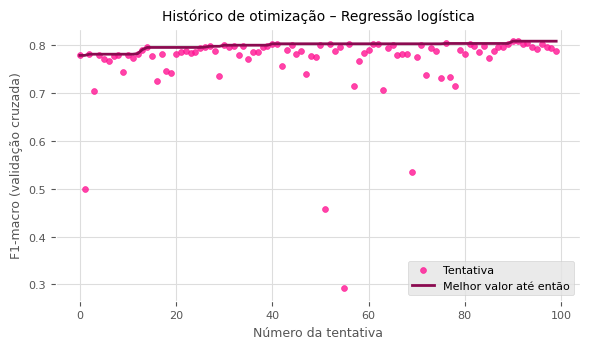

C:\Users\isabela2610062\AppData\Local\Temp\ipykernel_43336\3634916717.py:20: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_optimization_history(estudo)


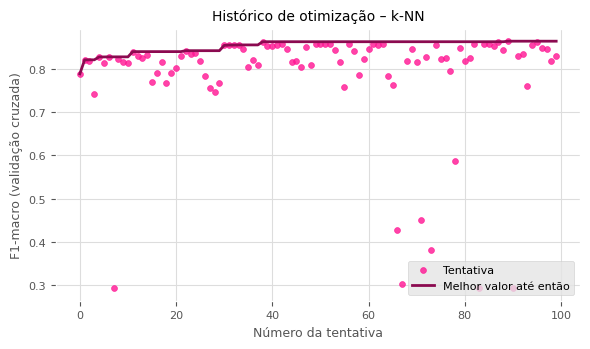

C:\Users\isabela2610062\AppData\Local\Temp\ipykernel_43336\3634916717.py:20: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_optimization_history(estudo)


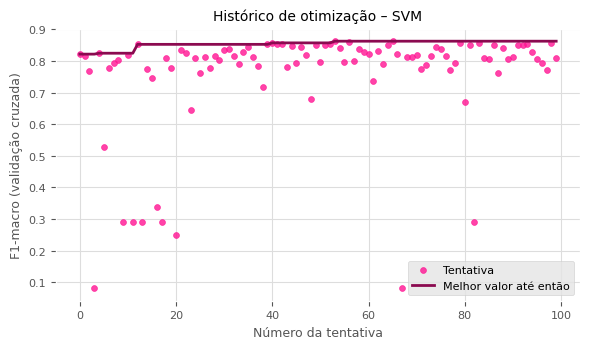

C:\Users\isabela2610062\AppData\Local\Temp\ipykernel_43336\3634916717.py:20: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_optimization_history(estudo)


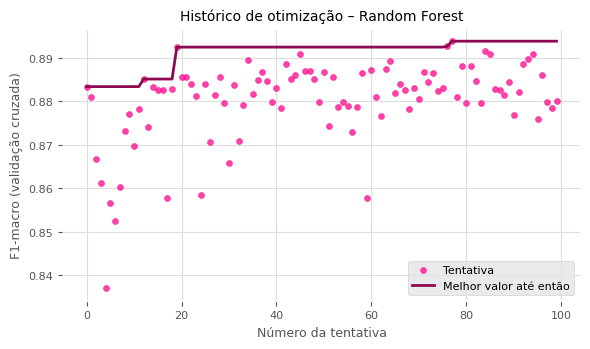

C:\Users\isabela2610062\AppData\Local\Temp\ipykernel_43336\3634916717.py:20: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_optimization_history(estudo)


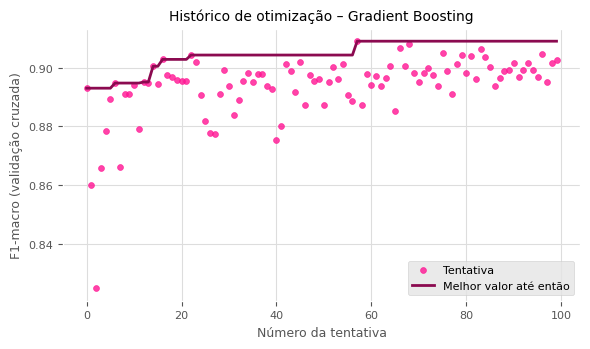

In [38]:
COR_ROSA = "deeppink"
COR_ROSA_ESCURO = "#8b0a50"

NOMES_ALGORITMOS = {
    "regressao_logistica": "Regressão logística",
    "knn": "k-NN",
    "svm": "SVM",
    "floresta_aleatoria": "Random Forest",
    "gradient_boosting": "Gradient Boosting",
}

def define_titulo(ax, texto):
    for posicao in ("left", "center", "right"):
        ax.set_title("", loc=posicao)
    ax.set_title(texto, fontsize=10)


def grafico_historico(estudo, nome, largura=6, altura=3.6):
    ax = plot_optimization_history(estudo)

    for conjunto in [a for a in ax.collections if isinstance(a, PathCollection)]:
        if conjunto.get_label() == "Objective Value":
            conjunto.set_color(COR_ROSA)
            conjunto.set_alpha(0.8)
            conjunto.set_sizes([18])
            conjunto.set_label("Tentativa")

    for linha in [a for a in ax.lines if isinstance(a, Line2D)]:
        if linha.get_label() == "Best Value":
            linha.set_color(COR_ROSA_ESCURO)
            linha.set_linewidth(2)
            linha.set_alpha(1)
            linha.set_zorder(5)
            linha.set_label("Melhor valor até então")

    ax.figure.set_size_inches(largura, altura)
    ax.set_facecolor("white")
    ax.grid(True, color="#dddddd")
    ax.legend(loc="lower right", fontsize=8)
    define_titulo(ax, f"Histórico de otimização – {nome}")
    ax.set_xlabel("Número da tentativa", fontsize=9)
    ax.set_ylabel("F1-macro (validação cruzada)", fontsize=9)
    ax.tick_params(labelsize=8)
    ax.figure.tight_layout()
    return ax


for algoritmo, estudo in estudos.items():
    grafico_historico(estudo, NOMES_ALGORITMOS[algoritmo])
    plt.show()

<p>
A regressão logística apresentou desempenho relativamente estável, mas limitado. Após cerca de 30 tentativas, o processo praticamente converge, indicando que a otimização dos hiperparâmetros produz apenas pequenos ganhos de desempenho.
</p>

<p>
O k-NN apresentou melhoria significativa em relação à regressão logística. Entretanto, mostrou elevada sensibilidade aos hiperparâmetros, evidenciada pela grande dispersão dos resultados obtidos durante a busca.
</p>

<p>
O SVM alcançou desempenho competitivo com o k-NN, porém também apresentou forte dependência da escolha dos hiperparâmetros. Configurações inadequadas podem degradar substancialmente o desempenho do modelo.
</p>

<p>
A Random Forest apresentou desempenho superior aos modelos anteriores e mostrou elevada robustez durante a otimização. A baixa dispersão dos resultados sugere que diferentes combinações de hiperparâmetros tendem a produzir desempenhos semelhantes.
</p>

<p>
O Gradient Boosting obteve o melhor desempenho geral, atingindo F1-macro superior a 0,90. Além disso, apresentou estabilidade durante a busca de hiperparâmetros, indicando boa capacidade de generalização e consistência do método para este conjunto de dados.
</p>

<h3>Melhores hiperparâmetros encontrados</h3>

<p align="justify"> A tabela a seguir mostra, para cada algoritmo, os hiperparâmetros da melhor tentativa, incluindo as escolhas de pré-processamento (normalizador e redução de dimensionalidade). </p>

In [39]:
linhas = []
for algoritmo, estudo in estudos.items():
    parametros = ", ".join(
        f"{nome}={round(valor, 4) if isinstance(valor, float) else valor}"
        for nome, valor in estudo.best_trial.params.items()
    )
    linhas.append({"algoritmo": algoritmo,
                   "melhor_tentativa": estudo.best_trial.number,
                   "parametros": parametros})

pd.set_option("display.max_colwidth", None)
melhores_parametros = pd.DataFrame(linhas).set_index("algoritmo")
melhores_parametros

,melhor_tentativa,parametros
algoritmo,,
regressao_logistica,90,"normalizador=robust, reducao=rfe, num_atributos_rfe=12, C=25.7217, razao_l1=0.0, peso_classes=None"
knn,89,"normalizador=standard, reducao=rfe, num_atributos_rfe=8, num_vizinhos=1, pesos=uniform, potencia_minkowski=1.204"
svm,53,"normalizador=standard, reducao=nenhuma, nucleo=rbf, C=23.0478, peso_classes=None, gamma=0.0583"
floresta_aleatoria,77,"reducao=nenhuma, num_arvores=134, profundidade_max=31, min_exemplos_split=4, min_exemplos_folha=1, max_atributos=0.5, criterio=entropy, peso_classes=balanced"
gradient_boosting,57,"reducao=nenhuma, taxa_aprendizado=0.1023, num_iteracoes=53, profundidade_max=6, max_folhas=30, min_exemplos_folha=5, regularizacao_l2=0.0105, peso_classes=balanced"


<h3>Gráficos da importância dos hiperparametros</h3>

<p align="justify"> 
A <strong>importância dos hiperparâmetros</strong> estima, a partir das tentativas realizadas, quanto cada hiperparâmetro influenciou o F1-macro, indicando quais merecem mais atenção. </p>

C:\Users\isabela2610062\AppData\Local\Temp\ipykernel_43336\3160329152.py:22: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_param_importances(estudo, evaluator=avaliador)


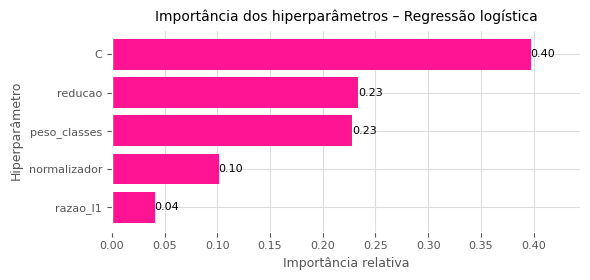

C:\Users\isabela2610062\AppData\Local\Temp\ipykernel_43336\3160329152.py:22: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_param_importances(estudo, evaluator=avaliador)


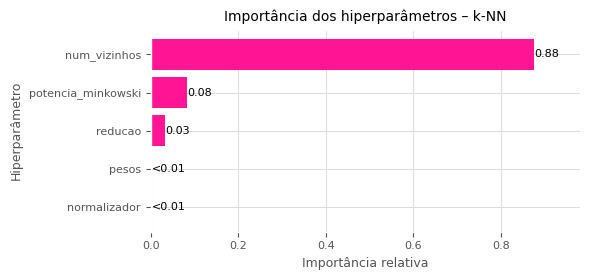

C:\Users\isabela2610062\AppData\Local\Temp\ipykernel_43336\3160329152.py:22: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_param_importances(estudo, evaluator=avaliador)


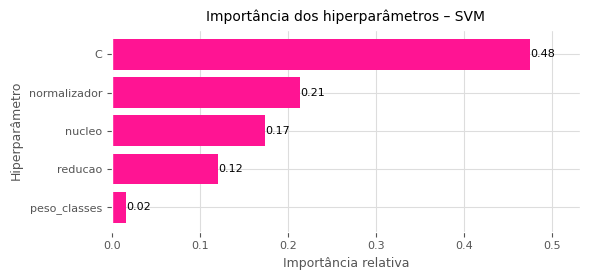

C:\Users\isabela2610062\AppData\Local\Temp\ipykernel_43336\3160329152.py:22: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_param_importances(estudo, evaluator=avaliador)


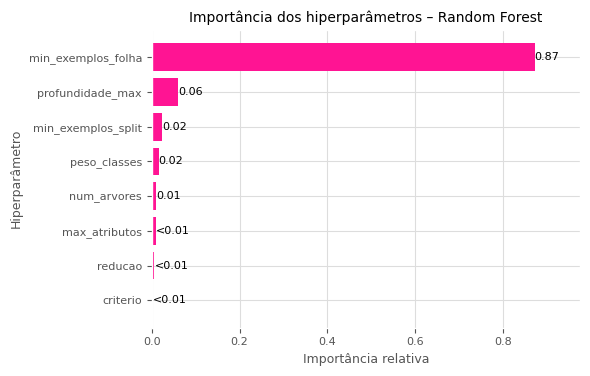

C:\Users\isabela2610062\AppData\Local\Temp\ipykernel_43336\3160329152.py:22: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_param_importances(estudo, evaluator=avaliador)


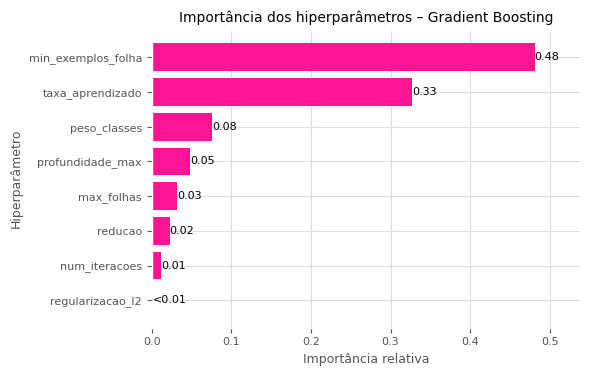

In [40]:
from optuna.visualization.matplotlib import plot_param_importances

COR_ROSA = "deeppink"

NOMES_ALGORITMOS = {
    "regressao_logistica": "Regressão logística",
    "knn": "k-NN",
    "svm": "SVM",
    "floresta_aleatoria": "Random Forest",
    "gradient_boosting": "Gradient Boosting",
}

avaliador = optuna.importance.FanovaImportanceEvaluator(seed=semente_aleatoria)

def define_titulo(ax, texto):
    for posicao in ("left", "center", "right"):
        ax.set_title("", loc=posicao)
    ax.set_title(texto, fontsize=10)


for algoritmo, estudo in estudos.items():
    ax = plot_param_importances(estudo, evaluator=avaliador)

    for barra in ax.patches:                       
        barra.set_facecolor(COR_ROSA)
    legenda = ax.get_legend()                     
    if legenda is not None:
        legenda.remove()
    for texto in ax.texts:                         
        texto.set_fontsize(8)

    ax.figure.set_size_inches(6, 0.32 * len(ax.patches) + 1.3)
    ax.set_facecolor("white")
    ax.grid(True, color="#dddddd")
    define_titulo(ax, f"Importância dos hiperparâmetros – {NOMES_ALGORITMOS[algoritmo]}")
    ax.set_xlabel("Importância relativa", fontsize=9)
    ax.set_ylabel("Hiperparâmetro", fontsize=9)
    ax.tick_params(labelsize=8)
    ax.figure.tight_layout()
    plt.show()

<p>
Na regressão logística, o hiperparâmetro mais importante foi <i>C</i> (0,40), indicando que a intensidade da regularização exerceu a maior influência sobre o desempenho do modelo. Em seguida, a técnica de redução de dimensionalidade (0,23) e o uso de pesos para as classes (0,23) também apresentaram contribuição relevante. Já o método de normalização (0,10) teve impacto medio, enquanto a razão entre penalizações L1 e L2 (0,04) mostrou influência praticamente desprezível. Esses resultados sugerem que o ajuste adequado da regularização é o principal fator para melhorar a capacidade preditiva da regressão logística.
</p>

<p>
Para o k-NN, o número de vizinhos foi o hiperparâmetro mais importante (0,88), concentrando quase toda a influência sobre o desempenho do modelo. A potência da distância de Minkowski apresentou contribuição reduzida (0,08), enquanto a redução de dimensionalidade (0,03), o esquema de pesos e o método de normalização tiveram quaseimpacto algum. Isso indica que a escolha do número de vizinhos é o principal aspecto a ser ajustado para obter bons resultados nesse algoritmo.
</p>

<p>
No SVM, o parâmetro <i>C</i> foi novamente o mais relevante (0,48), evidenciando a importância do controle da penalização dos erros de classificação. A normalização dos dados (0,21) e o tipo de núcleo utilizado (0,17) também contribuíram significativamente para o desempenho final. A redução de dimensionalidade apresentou influência moderada (0,12), enquanto os pesos das classes tiveram impacto muito pequeno (0,02). Dessa forma, o desempenho do SVM depende principalmente do equilíbrio entre regularização e transformação do espaço de atributos.
</p>

<p>
Na Random Forest, observa-se um predomínio absoluto do parâmetro de número mínimo de exemplos por folha (0,87), tornando-o o principal responsável pelas variações de desempenho observadas durante a otimização. A profundidade máxima das árvores apresentou influência muito menor (0,06), enquanto os demais hiperparâmetros contribuíram de forma praticamente irrelevante. Esse comportamento sugere que o controle da complexidade das folhas é o fator mais importante para evitar sobreajuste e obter melhor capacidade de generalização.
</p>

<p>
Para o Gradient Boosting, o número mínimo de exemplos por folha (0,48) e a taxa de aprendizado (0,33) foram os hiperparâmetros mais importantes, respondendo pela maior parte do desempenho alcançado. Os pesos das classes (0,08) e a profundidade máxima das árvores (0,05) tiveram influência secundária, enquanto os demais parâmetros apresentaram contribuição muito pequena. Esses resultados indicam que o equilíbrio entre a velocidade de aprendizado e a complexidade das árvores foi determinante para que o modelo atingisse o melhor desempenho entre todos os algoritmos avaliados.
</p>

<h2>Reavaliação dos melhores modelos e escolha do modelo final</h2>

<p align="justify"> O F1-macro de cada algoritmo na otimização é o do melhor entre 100 tentativas, o que tende a ser otimista, pois a configuração vencedora foi escolhida justamente por ter ido bem naquelas divisões. Para obter uma estimativa mais confiável, a melhor configuração de cada algoritmo foi <strong>reavaliada em uma nova validação cruzada estratificada, repetida 5 vezes (5 folds × 5 repetições = 25 avaliações)</strong>, com uma semente diferente da usada na otimização. Os dois modelos de referência (baseline) foram avaliados da mesma forma, para a comparação ser justa. Os resultados são apresentados como média ± desvio padrão das 25 avaliações. </p>

<p align="justify">
O modelo final é escolhido <strong>exclusivamente com base nos resultados dessa reavaliação</strong>, considerando o F1-macro médio como métrica principal. Quando os modelos apresentam resultados próximos nessa métrica, o recall da classe patológica é utilizado como critério de desempate, por representar a capacidade de identificar corretamente os exames de maior risco. O conjunto de teste não participa dessa escolha, permanecendo reservado para a avaliação final do modelo selecionado.
</p>

O código abaixo faz a validação cruzada estratificada de 5 folds e repete o processo 5 vezes com sorteios diferentes, gerando 25 avaliações e utilizando outra semente aleatória.

In [41]:
baselines = {
    "Dummy (classe mais frequente)": baseline,
    "Regressão logística simples": regressão_logistica_simples,
}

In [42]:
NUM_REPETICOES = 5
semente_reavaliacao = 24
cv_reavaliacao = RepeatedStratifiedKFold(n_splits=5, n_repeats=NUM_REPETICOES,
                                         random_state=semente_reavaliacao)

modelos_finais = {NOMES_ALGORITMOS[algoritmo]: cria_instancia_modelo(estudo.best_trial, algoritmo)
                  for algoritmo, estudo in estudos.items()}
modelos_comparados = {**baselines, **modelos_finais}

resultados_cv = {}
for nome, modelo in modelos_comparados.items():
    inicio = time.time()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        resultados_cv[nome] = cross_validate(modelo, X_treino, y_treino,
                                             cv=cv_reavaliacao, scoring=scoring)
    print(f"{nome}: {time.time() - inicio:.0f} s")

Dummy (classe mais frequente): 1 s
Regressão logística simples: 2 s
Regressão logística: 41 s
k-NN: 14 s
SVM: 3 s
Random Forest: 16 s
Gradient Boosting: 48 s


O código abaixo exibe a acuracia, f1_maco, a acurácia balanciada e o recall patologico de cada modelo

In [43]:
linhas = []
for nome, res in resultados_cv.items():
    linha = {"modelo": nome}
    for metrica in scoring:
        linha[f"{metrica}_media"] = res[f"test_{metrica}"].mean()
        linha[f"{metrica}_dp"] = res[f"test_{metrica}"].std()
    linhas.append(linha)
resumo_cv = pd.DataFrame(linhas).set_index("modelo")

tabela_cv = pd.DataFrame({
    metrica: resumo_cv[f"{metrica}_media"].map("{:.3f}".format) + " ± " + resumo_cv[f"{metrica}_dp"].map("{:.3f}".format)
    for metrica in scoring
})
tabela_cv

,acuracia,f1_macro,balanced_accuracy,recall_patologico
modelo,,,,
Dummy (classe mais frequente),0.779 ± 0.001,0.292 ± 0.000,0.333 ± 0.000,0.000 ± 0.000
Regressão logística simples,0.892 ± 0.012,0.789 ± 0.027,0.779 ± 0.033,0.739 ± 0.075
Regressão logística,0.891 ± 0.015,0.787 ± 0.028,0.778 ± 0.032,0.730 ± 0.073
k-NN,0.922 ± 0.011,0.854 ± 0.022,0.846 ± 0.026,0.846 ± 0.071
SVM,0.923 ± 0.015,0.862 ± 0.026,0.848 ± 0.030,0.844 ± 0.057
Random Forest,0.942 ± 0.013,0.895 ± 0.026,0.877 ± 0.027,0.900 ± 0.052
Gradient Boosting,0.946 ± 0.010,0.905 ± 0.019,0.898 ± 0.021,0.910 ± 0.042


O código abaixo calcula mostra a media da f1 macro, a f1 macro do modelo com a melhor combinação d hiperparametros e a média do recall patológico

In [44]:
nomes_otimizados = list(modelos_finais)
ranking = (resumo_cv.loc[nomes_otimizados, ["f1_macro_media", "f1_macro_dp", "recall_patologico_media"]]
           .sort_values("f1_macro_media", ascending=False))
melhor_modelo = ranking.index[0]
diferenca = ranking["f1_macro_media"].iloc[0] - ranking["f1_macro_media"].iloc[1]

print(ranking.round(3))
print(f"\nEscolhido: {melhor_modelo}")
print(f"Diferença de F1-macro para o 2º colocado: {diferenca:.3f} "
      f"(desvio padrão do escolhido: {ranking['f1_macro_dp'].iloc[0]:.3f})")

                     f1_macro_media  f1_macro_dp  recall_patologico_media
modelo                                                                   
Gradient Boosting             0.905        0.019                    0.910
Random Forest                 0.895        0.026                    0.900
SVM                           0.862        0.026                    0.844
k-NN                          0.854        0.022                    0.846
Regressão logística           0.787        0.028                    0.730

Escolhido: Gradient Boosting
Diferença de F1-macro para o 2º colocado: 0.010 (desvio padrão do escolhido: 0.019)


<p align="justify">
Na reavaliação dos modelos utilizando validação cruzada, o melhor desempenho médio em termos de F1-score macro foi obtido pelo <strong>Gradient Boosting</strong> 0,905, seguido pelo <strong>Random Forest</strong> 0,895. Embora o Gradient Boosting tenha apresentado o maior valor médio, a diferença de 0,010 em relação ao Random Forest é pequena diante da variabilidade observada nos resultados. Dessa forma, os dois algoritmos apresentaram desempenhos próximos nessa avaliação.
</p>

<p align="justify">
Os modelos k-NN, SVM, Random Forest e Gradient Boosting superaram a regressão logística simples (F1-macro de 0,789 na reavaliação), enquanto a regressão logística otimizada (0,787) apresentou resultado semelhante. O ganho observado durante a otimização da regressão logística, de 0,778 para 0,808, não se confirmou nas novas divisões. Isso evidencia a importância de reavaliar os modelos em partições diferentes daquelas utilizadas na busca de hiperparâmetros.
</p>

<p align="justify">
O modelo selecionado foi o <strong>Gradient Boosting</strong>, que apresentou o maior F1-score macro médio (0,905 ± 0,019) e recall patológico de 0,910 ± 0,042. Apesar da proximidade com a Random Forest, que obteve F1-macro de 0,895 ± 0,026 e recall patológico de 0,900, o Gradient Boosting apresentou resultados ligeiramente superiores nas duas métricas. Assim, sua escolha considerou tanto o desempenho geral quanto a capacidade de identificar corretamente os exames patológicos.
</p>

<h3>Comparação dos modelos com o baseline</h3>

<p align="justify"> O gráfico a seguir mostra, para cada modelo, a distribuição do F1-macro e do recall da classe patológica nas 25 avaliações da validação cruzada repetida. Em cada <em>boxplot</em>, a linha central é a mediana, a caixa cobre os 50% centrais das avaliações e os pontos isolados são avaliações atípicas. Os modelos estão ordenados pelo F1-macro médio. Em cinza estão os baselines, em rosa os modelos otimizados e em rosa escuro o modelo escolhido. </p>

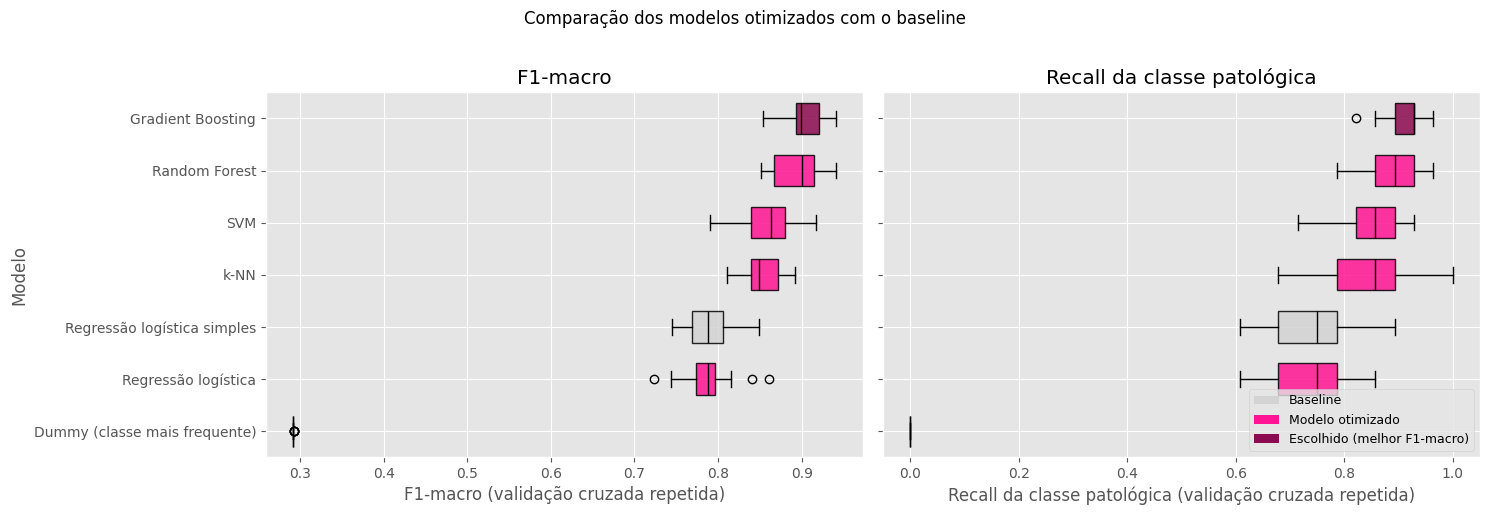

In [45]:
ordem_modelos = resumo_cv["f1_macro_media"].sort_values(ascending=False).index.tolist()
cor_de = {nome: ("lightgray" if nome in baselines else "deeppink") for nome in ordem_modelos}
cor_de[melhor_modelo] = "#8b0a50"

fig, eixos = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, (metrica, rotulo) in zip(eixos, [("f1_macro", "F1-macro"),
                                         ("recall_patologico", "Recall da classe patológica")]):
    valores = [resultados_cv[nome][f"test_{metrica}"] for nome in ordem_modelos]
    caixas = ax.boxplot(valores, vert=False, patch_artist=True, widths=0.6)
    for caixa, nome in zip(caixas["boxes"], ordem_modelos):
        caixa.set_facecolor(cor_de[nome])
        caixa.set_alpha(0.85)
    for mediana in caixas["medians"]:
        mediana.set_color("black")
    ax.set_yticks(range(1, len(ordem_modelos) + 1))
    ax.set_yticklabels(ordem_modelos)
    ax.set_xlabel(f"{rotulo} (validação cruzada repetida)")
    ax.set_title(rotulo)

eixos[0].invert_yaxis()  
eixos[0].set_ylabel("Modelo")
eixos[1].legend(handles=[Patch(facecolor="lightgray", label="Baseline"),
                         Patch(facecolor="deeppink", label="Modelo otimizado"),
                         Patch(facecolor="#8b0a50", label="Escolhido (melhor F1-macro)")],
                loc="lower right", fontsize=9)
fig.suptitle("Comparação dos modelos otimizados com o baseline", y=1.02)
plt.tight_layout()
plt.show()

<p align="justify"> O gráfico mostra que K-nn, SVM, Random Forest e Gradient Boosting se separam claramente do baseline em F1-macro, enquanto a regressão logística e a regressão logística simples ficam próximos entre si, com caixas sobrepostas. Em recall da classe patológicao, Gradient Boosting apresenta a maior mediana, seguido de perto pelo Random Forest. O modelo k-NN exibe a maior dispersão dos resultados, indicando maior sensibilidade às diferentes partições dos dados e, consequentemente, menor estabilidade. Em contraste, Gradient Boosting e Random Forest apresentam distribuições mais concentradas, sugerindo maior robustez e consistência no desempenho. </p>

<h3>Matrizes de confusão de todos os modelos</h3>

<p align="justify"> A tabela de métricas resume o desempenho de cada modelo em um único número, mas não mostra <strong>onde</strong> cada um erra. A <strong>matriz de confusão</strong> faz esse detalhamento: cada linha é a classe real do exame (normal, suspeito ou patológico) e cada coluna é a classe prevista pelo modelo. A diagonal principal contém os acertos, e as demais células mostram quais classes estão sendo confundidas. </p>

<p align="justify"> Serão geradas matrizes para os <strong>sete modelos</strong> comparados: os dois baselines (Dummy e regressão logística simples) e os cinco modelos otimizados com o Optuna (regressão logística, k-NN, SVM, Random Forest e Gradient Boosting). Para cada um, serão mostradas duas versões lado a lado: o <strong>número de exames</strong> em cada célula e a <strong>proporção por classe real</strong>, em que a diagonal corresponde ao recall de cada classe. A versão em proporção é a mais indicada para comparar modelos, pois não depende de quantos exames há em cada classe. </p>

<p align="justify"> As previsões vêm de uma <strong>validação cruzada estratificada de 5 folds no conjunto de treino</strong>, com <code>cross_val_predict</code>. Assim, cada exame é previsto por um modelo que não o viu durante o treinamento, e todos os 1.690 exames de treino entram na matriz. Foi usada a semente da reavaliação (diferente da semente da otimização), para que as divisões não sejam as mesmas em que os hiperparâmetros foram escolhidos, o que daria uma visão mais otimista do desempenho. O <strong>conjunto de teste não é utilizado aqui</strong>: ele continua reservado para a avaliação final, feita uma única vez, apenas com o modelo escolhido. </p>

<p align="justify"> Como o erro clinicamente mais grave é classificar um exame <strong>patológico como normal</strong>, ao final de cada matriz é impressa a quantidade desses casos, e uma tabela-resumo reúne esse número, os patológicos classificados como suspeitos, os suspeitos classificados como normais e o recall patológico de todos os modelos. O objetivo é verificar quais modelos erram menos nos casos de risco e se os erros se concentram entre classes vizinhas. </p>

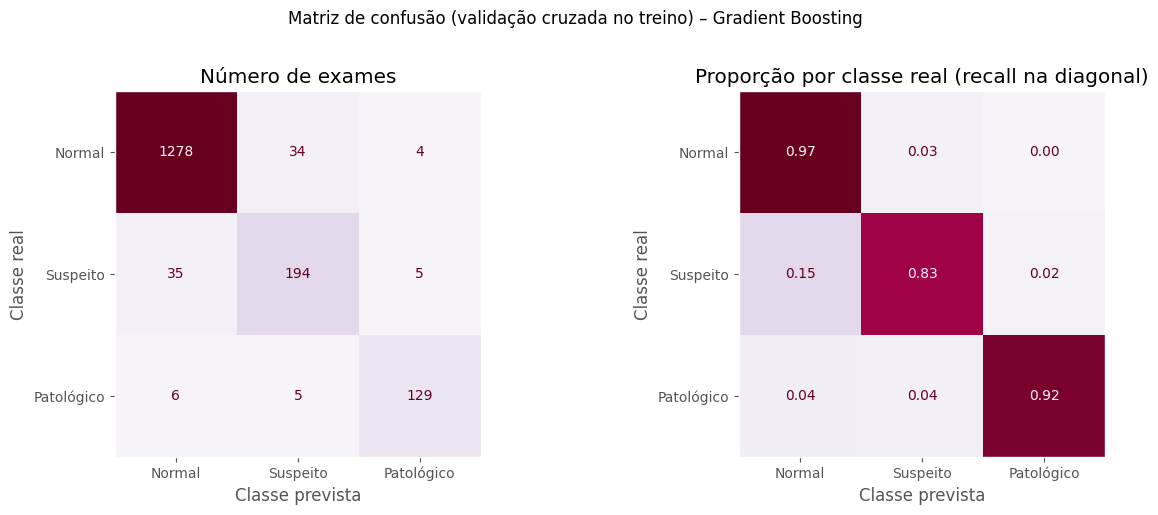

Exames patológicos classificados como normais: 6 de 140


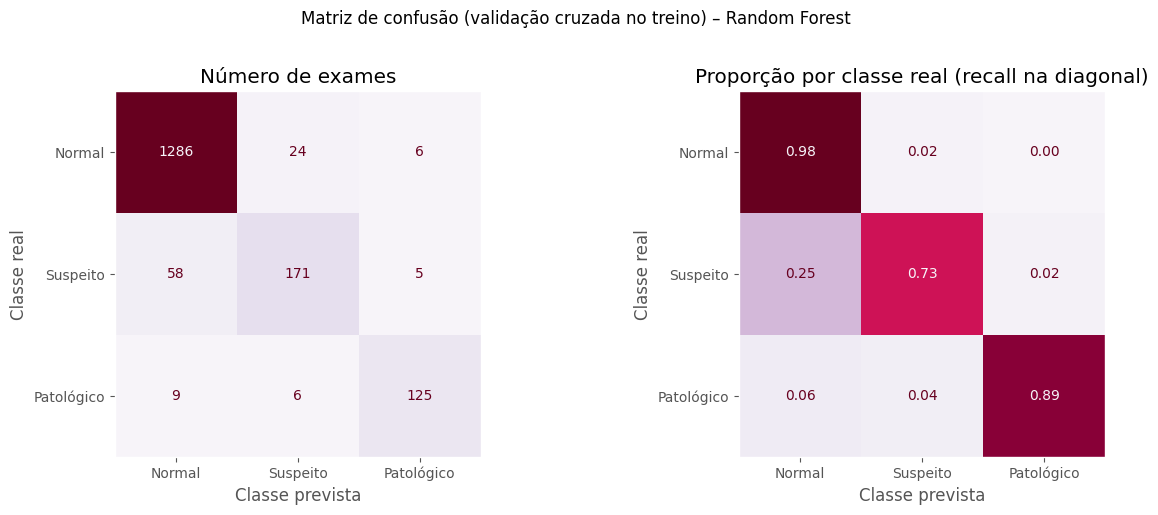

Exames patológicos classificados como normais: 9 de 140


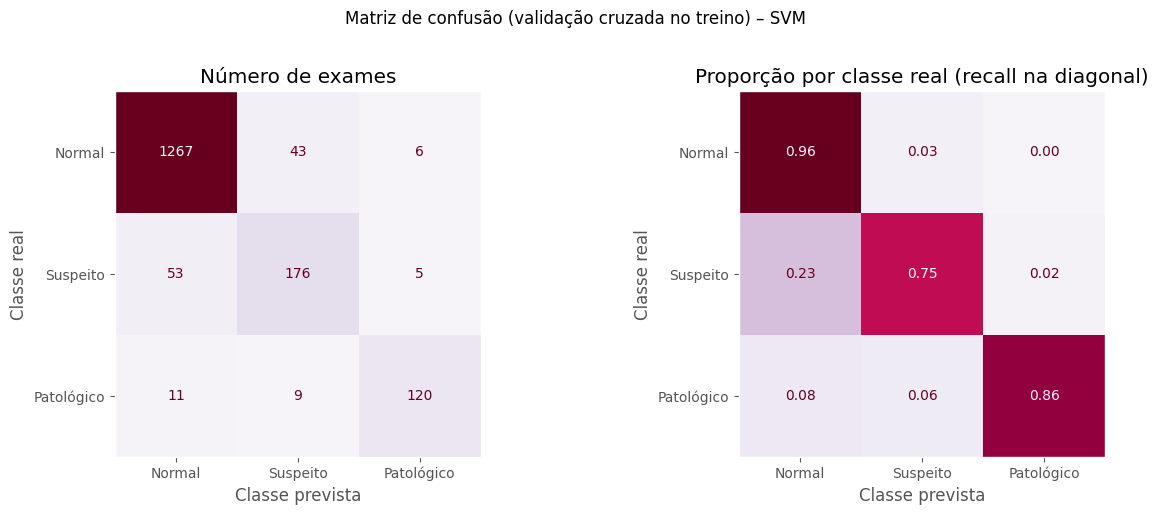

Exames patológicos classificados como normais: 11 de 140


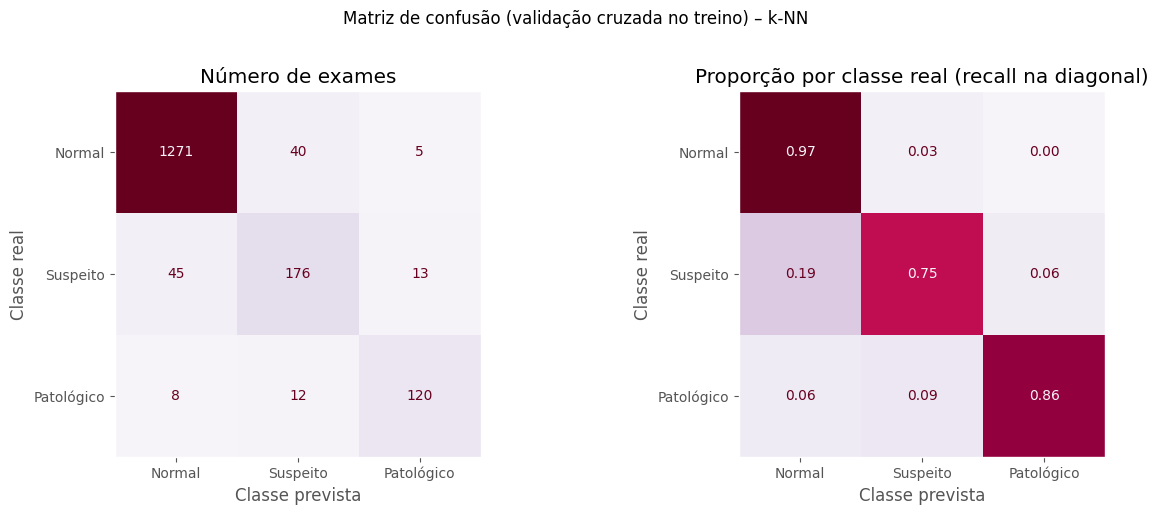

Exames patológicos classificados como normais: 8 de 140


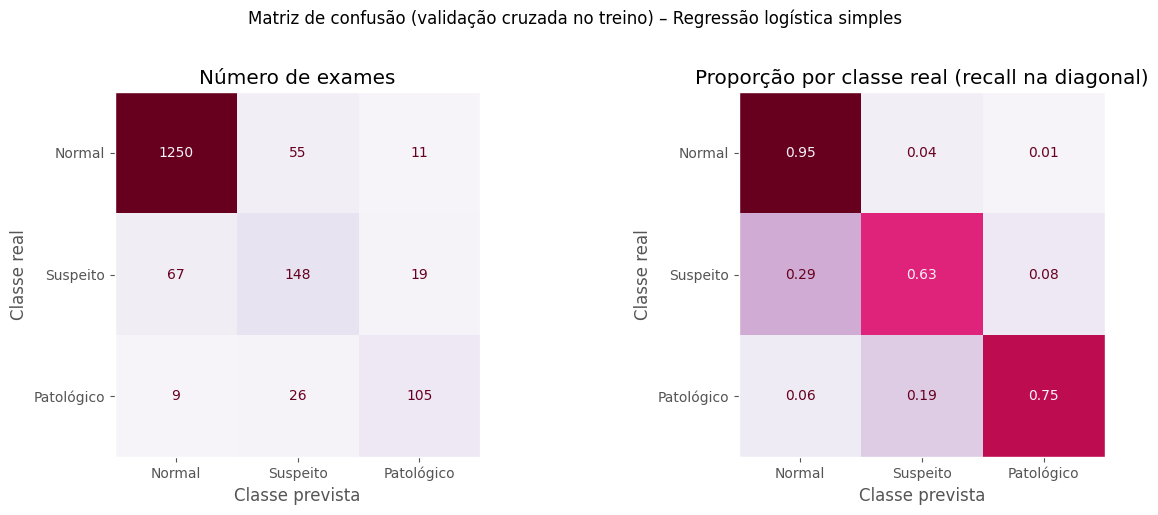

Exames patológicos classificados como normais: 9 de 140


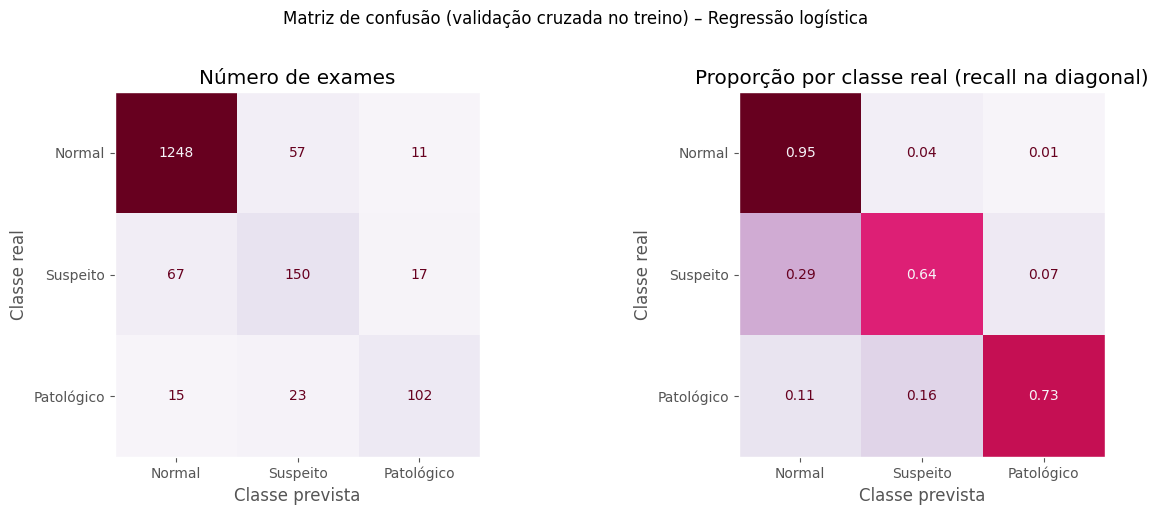

Exames patológicos classificados como normais: 15 de 140


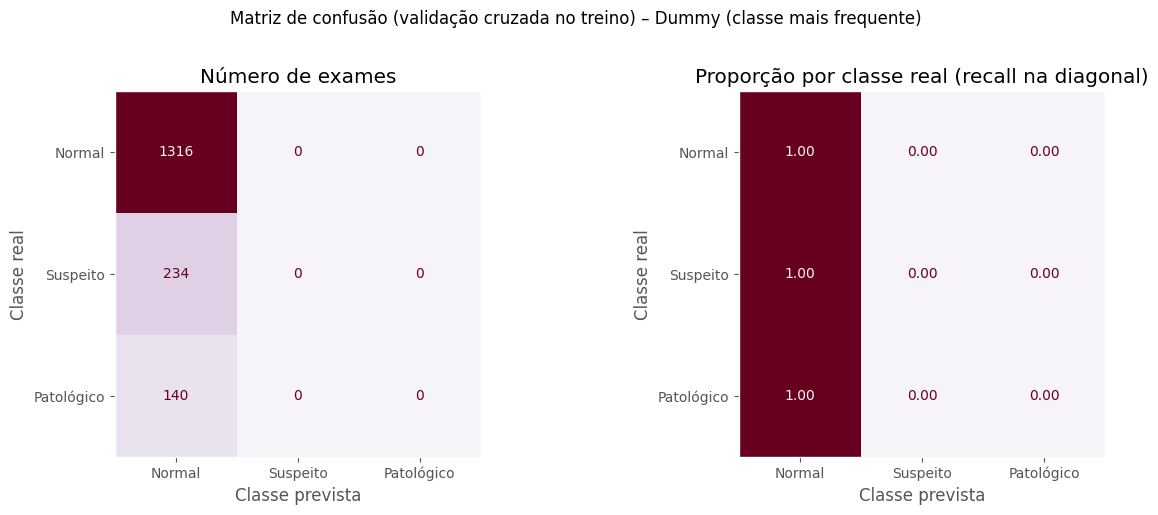

Exames patológicos classificados como normais: 140 de 140


,patológico → normal,patológico → suspeito,suspeito → normal,nº de patológicos,recall patológico
modelo,,,,,
Gradient Boosting,6,5,35,140,0.921
Random Forest,9,6,58,140,0.893
SVM,11,9,53,140,0.857
k-NN,8,12,45,140,0.857
Regressão logística simples,9,26,67,140,0.750
Regressão logística,15,23,67,140,0.729
Dummy (classe mais frequente),140,0,234,140,0.000


In [46]:

cv_matrizes = StratifiedKFold(n_splits=5, shuffle=True, random_state=semente_reavaliacao)

previsoes_cv = {}
for nome in ordem_modelos:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        previsoes_cv[nome] = cross_val_predict(modelos_comparados[nome], X_treino, y_treino,
                                               cv=cv_matrizes)
for nome, y_prev in previsoes_cv.items():
    fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
    ConfusionMatrixDisplay.from_predictions(y_treino, y_prev, display_labels=ordem,
                                            cmap="PuRd", ax=eixos[0], colorbar=False)
    eixos[0].set_title("Número de exames")
    ConfusionMatrixDisplay.from_predictions(y_treino, y_prev, display_labels=ordem,
                                            normalize="true", values_format=".2f",
                                            cmap="PuRd", ax=eixos[1], colorbar=False)
    eixos[1].set_title("Proporção por classe real (recall na diagonal)")
    for ax in eixos:
        ax.set_xlabel("Classe prevista")
        ax.set_ylabel("Classe real")
        ax.grid(False)
    fig.suptitle(f"Matriz de confusão (validação cruzada no treino) – {nome}", y=1.02)
    plt.tight_layout()
    plt.show()

    cm = confusion_matrix(y_treino, y_prev, labels=[1, 2, 3])
    print(f"Exames patológicos classificados como normais: {cm[2, 0]} de {cm[2].sum()}")

linhas = []
for nome, y_prev in previsoes_cv.items():
    cm = confusion_matrix(y_treino, y_prev, labels=[1, 2, 3])
    linhas.append({
        "modelo": nome,
        "patológico → normal": cm[2, 0],
        "patológico → suspeito": cm[2, 1],
        "suspeito → normal": cm[1, 0],
        "nº de patológicos": cm[2].sum(),
        "recall patológico": round(cm[2, 2] / cm[2].sum(), 3),
    })
pd.DataFrame(linhas).set_index("modelo")

<p align="justify">
Entre os modelos avaliados, o Gradient Boosting apresentou o melhor desempenho geral. O algoritmo foi capaz de identificar corretamente cerca de 97% dos exames classificados como Normais, 83% dos exames Suspeitos e 92% dos exames Patológicos. Considerando que os casos patológicos representam a situação de maior risco, o resultado é relevante: dos 140 exames dessa classe, apenas 11 foram classificados incorretamente. Desses, 6 foram confundidos com exames Normais e 5 com exames Suspeitos, demonstrando a capacidade do modelo de reconhecer a maioria dos casos patológicos.
</p>

<p align="justify">
A Random Forest também apresentou resultados consistentes, ficando próxima do Gradient Boosting. O modelo alcançou aproximadamente 98% de recall para a classe Normal e 89% para a classe Patológico. Entretanto, seu desempenho foi mais limitado na identificação dos exames Suspeitos, com recall de cerca de 73%. Parte dos casos intermediários foi classificada como Normal, dificultando a distinção entre situações saudáveis e aquelas que merecem maior atenção.
</p>

<p align="justify">
Os algoritmos SVM e k-NN apresentaram comportamentos semelhantes. Ambos alcançaram aproximadamente 86% de recall para a classe Patológico e cerca de 75% para a classe Suspeito. Ao analisar as matrizes de confusão, observa-se que os erros ocorreram principalmente na classificação de exames Suspeitos como Normais, com 53 e 45 ocorrências nos dois modelos. Já os casos Patológicos classificados como Suspeitos foram menos frequentes, com 9 e 12 ocorrências. Portanto, a maior dificuldade desses algoritmos esteve na identificação dos casos intermediários.
</p>

<p align="justify">
As versões da regressão logística apresentaram os resultados mais modestos entre os modelos avaliados. Embora tenham mantido bom desempenho na identificação dos exames Normais, com recalls próximos de 95%, mostraram maior dificuldade para reconhecer corretamente os casos Suspeitos e Patológicos. A regressão logística simples atingiu aproximadamente 75% de recall para a classe Patológico, enquanto a versão otimizada obteve cerca de 73%. Esses resultados sugerem que modelos lineares apresentam limitações para representar algumas das relações mais complexas presentes no conjunto de dados.
</p>

<p align="justify">
Ao observar especificamente os erros mais críticos, isto é, os exames Patológicos classificados como Normais, o Gradient Boosting apresentou o menor número de ocorrências, com 6 casos. Em seguida aparecem k-NN (8 casos), Random Forest (9 casos) e SVM (11 casos). Embora o Gradient Boosting tenha se destacado nesse aspecto, as diferenças entre os modelos foram relativamente pequenas e devem ser interpretadas considerando também as proporções de acerto de cada classe.
</p>

<p align="justify">
De forma geral, os resultados mostram que os modelos apresentaram diferentes níveis de sucesso na distinção entre as classes Normal, Suspeito e Patológico. O Gradient Boosting se destacou pelo desempenho geral e pela capacidade de reconhecer os casos patológicos, enquanto a Random Forest também apresentou resultados competitivos. A análise das matrizes de confusão complementa as métricas de avaliação, permitindo compreender melhor os tipos de erros cometidos por cada algoritmo.
</p>

<h2>Avaliação final no conjunto de teste</h2>

<p align="justify">
O conjunto de teste, reservado desde o início, é utilizado agora <strong>uma única vez</strong> para obter uma medida final do desempenho do modelo escolhido. O modelo foi treinado com todo o conjunto de treino e avaliado em exames que não participaram de seu treinamento. São apresentadas métricas como F1-macro, balanced accuracy e recall da classe patológica, permitindo avaliar tanto o desempenho geral quanto a capacidade de identificar os casos de maior risco. Apenas para referência, os baselines também são avaliados no teste, sem que seus resultados sejam utilizados em nenhuma decisão. Os demais modelos otimizados <strong>não</strong> são avaliados nesse conjunto, pois isso permitiria escolher o modelo com base nos resultados do teste, comprometendo a avaliação final.
</p>

In [47]:
def medidas_teste(y_real, y_previsto):
    return {
        "acuracia": accuracy_score(y_real, y_previsto),
        "f1_macro": f1_score(y_real, y_previsto, average="macro"),
        "balanced_accuracy": balanced_accuracy_score(y_real, y_previsto),
        "recall_patologico": recall_score(y_real, y_previsto, labels=[3], average="macro", zero_division=0),
    }


modelo_escolhido = modelos_finais[melhor_modelo]
modelo_escolhido.fit(X_treino, y_treino)           
y_previsto = modelo_escolhido.predict(X_teste)     

medidas = {f"{melhor_modelo} (escolhido)": medidas_teste(y_teste, y_previsto)}
for nome, modelo in baselines.items():             
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        modelo.fit(X_treino, y_treino)
        medidas[f"{nome} (referência)"] = medidas_teste(y_teste, modelo.predict(X_teste))

pd.DataFrame(medidas).T.round(3)

,acuracia,f1_macro,balanced_accuracy,recall_patologico
Gradient Boosting (escolhido),0.969,0.953,0.935,1.000
Dummy (classe mais frequente) (referência),0.780,0.292,0.333,0.000
Regressão logística simples (referência),0.889,0.788,0.761,0.771


In [48]:
print(classification_report(y_teste, y_previsto, target_names=ordem, digits=3, zero_division=0))

              precision    recall  f1-score   support

      Normal      0.968     0.994     0.981       330
    Suspeito      0.959     0.810     0.879        58
  Patológico      1.000     1.000     1.000        35

    accuracy                          0.969       423
   macro avg      0.976     0.935     0.953       423
weighted avg      0.969     0.969     0.968       423



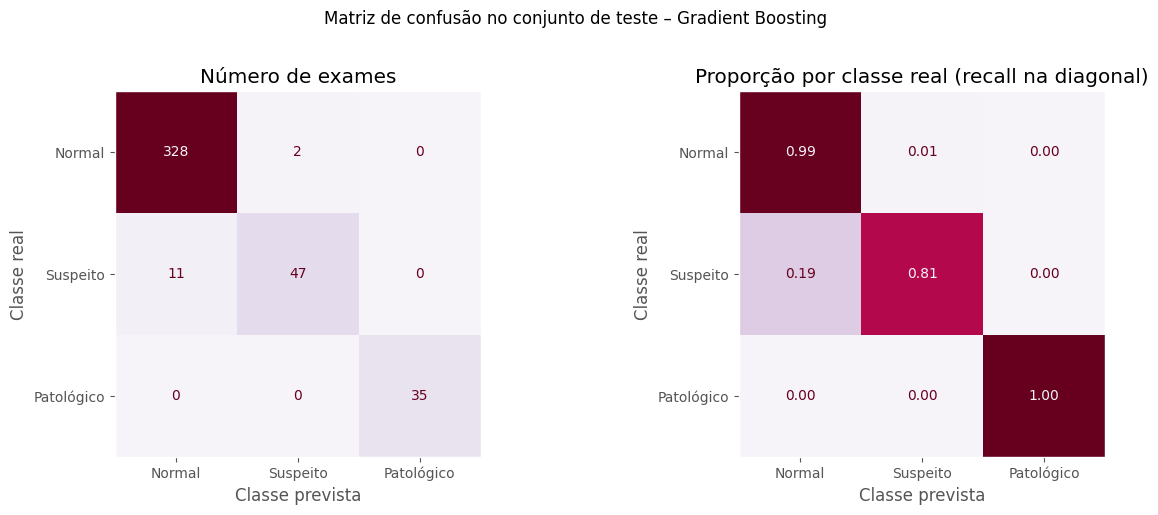

Exames patológicos classificados como normais: 0 de 35


In [49]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_teste, y_previsto, display_labels=ordem,
                                        cmap="PuRd", ax=eixos[0], colorbar=False)
eixos[0].set_title("Número de exames")
ConfusionMatrixDisplay.from_predictions(y_teste, y_previsto, display_labels=ordem,
                                        normalize="true", values_format=".2f",
                                        cmap="PuRd", ax=eixos[1], colorbar=False)
eixos[1].set_title("Proporção por classe real (recall na diagonal)")
for ax in eixos:
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")
    ax.grid(False)
fig.suptitle(f"Matriz de confusão no conjunto de teste – {melhor_modelo}", y=1.02)
plt.tight_layout()
plt.show()

cm = confusion_matrix(y_teste, y_previsto, labels=[1, 2, 3])
print(f"Exames patológicos classificados como normais: {cm[2, 0]} de {cm[2].sum()}")


<p align="justify"> No conjunto de teste, o modelo escolhido obteve F1-macro de <strong>0,953</strong>  e balanced accuracy de <strong>0,935</strong>. O recall da classe patológica foi de <strong>1,000 (35 de 35 exames patológicos identificados)</strong>. Os erros se concentraram na classe suspeita: 11 exames suspeitos foram classificados como normais e 2 exames normais foram classificados como suspeitos. Nenhum exame patológico foi classificado como normal, o erro mais grave neste problema. </p>

<p align="justify">
A matriz de confusão mostra que <strong>nenhum dos 35 exames patológicos foi classificado como normal</strong>, evitando o erro considerado mais grave neste problema. Os erros observados concentraram-se principalmente entre as classes <strong>Normal</strong> e <strong>Suspeito</strong>, em especial devido a 11 exames suspeitos classificados como normais e 2 exames normais classificados como suspeitos. Esses resultados indicam que o modelo apresenta elevada capacidade de detectar a classe patológica, embora ainda encontre dificuldades para distinguir perfeitamente casos suspeitos de casos normais.
</p>

<p align="justify">
Como o conjunto de teste contém apenas <strong>35 exames patológicos</strong>, a estimativa do recall dessa classe deve ser interpretada com cautela. Apesar do valor observado de 100%, amostras pequenas podem produzir estimativas otimistas e variações mais pronunciadas em novas coletas de dados. Assim, o resultado deve ser entendido principalmente como uma indicação da elevada capacidade do modelo em identificar casos patológicos, e não como uma garantia de desempenho perfeito em aplicações futuras.
</p>

<h2>Explicação do modelo: permutation importance</h2>

<p align="justify"> Para entender em quais atributos o modelo escolhido se apoia, foi usada a <strong>importância por permutação</strong> (<em>permutation importance</em>). O método funciona assim: mede-se o desempenho do modelo nos dados de teste; em seguida, os valores de <strong>um</strong> atributo são embaralhados aleatoriamente entre os exames, o que destrói a relação desse atributo com a classe, mantendo os demais intactos; e mede-se novamente o desempenho. A <strong>queda do desempenho</strong> é a importância do atributo: se embaralhá-lo piora muito o modelo, o modelo dependia dele; se quase não muda, o atributo contribui pouco. O processo foi repetido 30 vezes por atributo, e são mostradas a média e o desvio padrão da queda. </p>

<p align="justify"> A importância foi calculada para duas métricas, o F1-macro e o recall da classe patológica, que é a mais relevante clinicamente. Como o método é aplicado ao <em>pipeline</em> completo, os atributos embaralhados são os 21 originais, mesmo que o modelo use seleção de atributos ou PCA internamente. Duas limitações devem ser consideradas: quando há atributos fortemente correlacionados (como <code>histogram_mean</code>, <code>histogram_median</code> e <code>histogram_mode</code>), o modelo pode compensar o atributo embaralhado com os outros, e a importância de cada um fica subestimada; e, como o teste tem poucos exames patológicos, a importância para o recall é mais ruidosa. O método descreve o que o <em>modelo</em> usa, e não relações causais. </p>

In [50]:
scoring_perm = {
    "f1_macro": "f1_macro",
    "recall_patologico": make_scorer(recall_score, labels=[3], average="macro", zero_division=0),
}

resultado_perm = permutation_importance(
    modelo_escolhido, X_teste, y_teste,
    scoring=scoring_perm, n_repeats=30, random_state=semente_aleatoria, n_jobs=-1,
)

importancias = pd.DataFrame({
    "f1_macro_media": resultado_perm["f1_macro"].importances_mean,
    "f1_macro_dp": resultado_perm["f1_macro"].importances_std,
    "recall_media": resultado_perm["recall_patologico"].importances_mean,
    "recall_dp": resultado_perm["recall_patologico"].importances_std,
}, index=atributos)

importancias.sort_values("f1_macro_media", ascending=False).round(3)

,f1_macro_media,f1_macro_dp,recall_media,recall_dp
abnormal_short_term_variability,0.188,0.024,0.210,0.041
percentage_of_time_with_abnormal_long_term_variability,0.116,0.013,0.174,0.015
accelerations,0.114,0.017,0.129,0.048
histogram_mean,0.049,0.008,0.154,0.023
histogram_median,0.038,0.006,0.141,0.027
uterine_contractions,0.032,0.011,0.083,0.026
mean_value_of_short_term_variability,0.019,0.008,0.000,0.000
histogram_mode,0.015,0.006,0.037,0.015
baseline_value,0.014,0.006,0.005,0.011
histogram_number_of_peaks,0.011,0.007,0.002,0.007


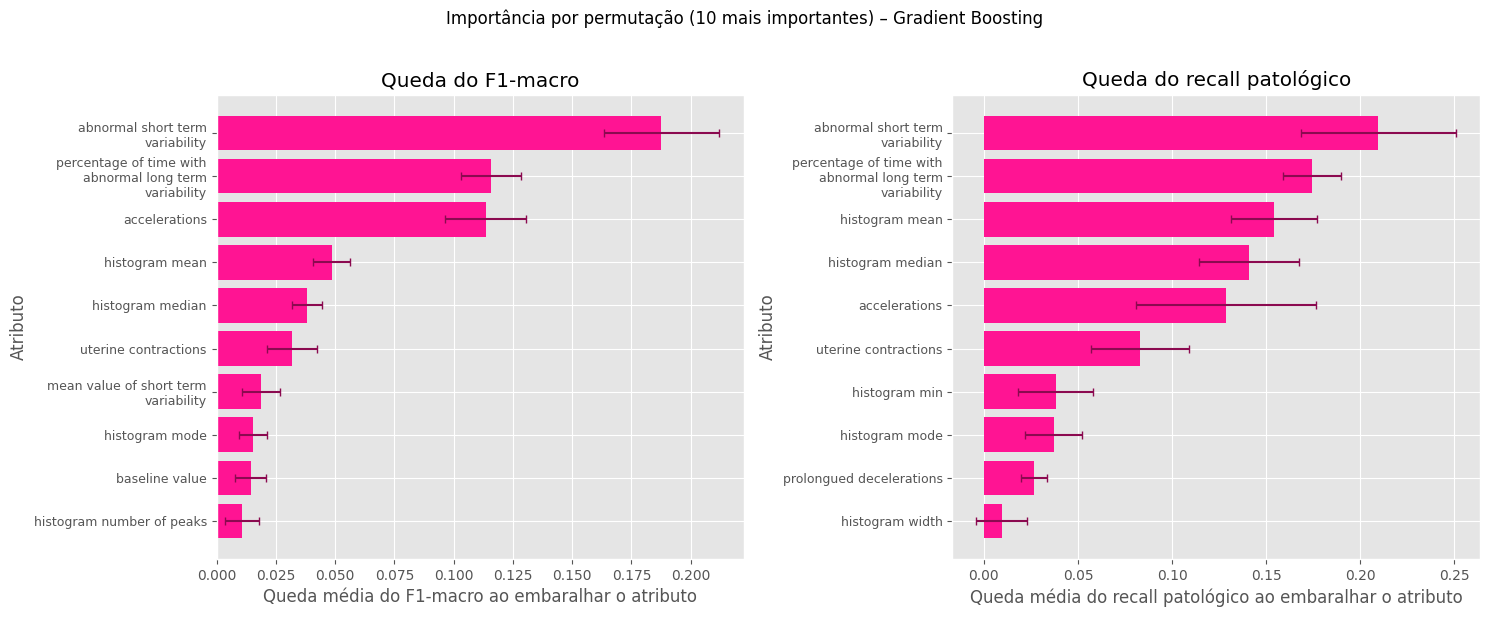

In [51]:
def barras_permutacao(ax, coluna_media, coluna_dp, titulo, rotulo_x, n=10):
    topo = importancias.sort_values(coluna_media, ascending=False).head(n).iloc[::-1]
    ax.barh(topo.index, topo[coluna_media], xerr=topo[coluna_dp],
            color="deeppink", ecolor="#8b0a50", capsize=3)
    ax.set_yticks(range(len(topo)))
    ax.set_yticklabels([textwrap.fill(nome.replace("_", " "), 26) for nome in topo.index], fontsize=9)
    ax.set_xlabel(rotulo_x)
    ax.set_ylabel("Atributo")
    ax.set_title(titulo)


fig, eixos = plt.subplots(1, 2, figsize=(15, 6))
barras_permutacao(eixos[0], "f1_macro_media", "f1_macro_dp", "Queda do F1-macro",
                  "Queda média do F1-macro ao embaralhar o atributo")
barras_permutacao(eixos[1], "recall_media", "recall_dp", "Queda do recall patológico",
                  "Queda média do recall patológico ao embaralhar o atributo")
fig.suptitle(f"Importância por permutação (10 mais importantes) – {melhor_modelo}", y=1.02)
plt.tight_layout()
plt.show()

<p align="justify">
Para o F1-macro, os atributos mais importantes foram <strong>abnormal short term variability</strong>, <strong>percentage of time with abnormal long term variability</strong> e <strong>accelerations</strong>. A permutação dessas variáveis provoca as maiores quedas de desempenho, indicando forte contribuição para a classificação geral.
</p>

<p align="justify">
Para o recall da classe patológica, destacaram-se <strong>abnormal short term variability</strong>, <strong>percentage of time with abnormal long term variability</strong>, <strong>histogram mean</strong> e <strong>histogram median</strong>. Isso sugere que essas variáveis são particularmente importantes para identificar corretamente os casos patológicos.
</p>

<p align="justify">
Os atributos <strong>histogram number of peaks</strong>, <strong>baseline value</strong> e <strong>histogram width</strong> apresentaram importância próxima de zero, indicando baixa contribuição marginal ao modelo. A menor importância individual de algumas variáveis derivadas do histograma pode estar relacionada à redundância entre elas, já que medidas como média, mediana e moda carregam informações semelhantes.
</p>

<h3>Comparação com a análise exploratória</h3>

<p align="justify"> A importância por permutação é comparada à correlação de Spearman de cada atributo com o alvo, calculada na análise exploratória (aqui recalculada apenas no conjunto de treino). As duas medidas respondem a perguntas diferentes: a correlação de Spearman mede a associação <strong>isolada</strong> do atributo com a classe, enquanto a importância por permutação mede o quanto o <strong>modelo</strong> depende do atributo, considerando as interações e a redundância entre atributos. Por isso, não se espera que os rankings coincidam: um atributo com correlação baixa pode ser importante em combinação com outros, e um atributo muito correlacionado com a classe pode ter importância baixa se outro atributo carregar a mesma informação. </p>

                                                        importancia_permutacao  \
abnormal_short_term_variability                                          0.188   
percentage_of_time_with_abnormal_long_term_variability                   0.116   
accelerations                                                            0.114   
histogram_mean                                                           0.049   
histogram_median                                                         0.038   
uterine_contractions                                                     0.032   
mean_value_of_short_term_variability                                     0.019   
histogram_mode                                                           0.015   

                                                        rho_spearman_abs  \
abnormal_short_term_variability                                    0.504   
percentage_of_time_with_abnormal_long_term_variability             0.384   
accelerations                    

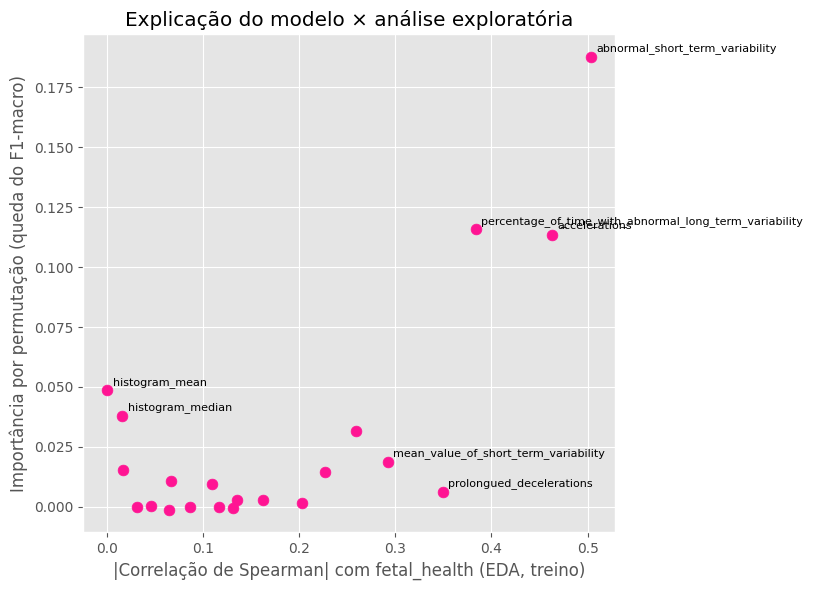

In [52]:
rho_alvo = df_treino.corr(method="spearman")["fetal_health"].drop("fetal_health")

comparacao = pd.DataFrame({
    "importancia_permutacao": importancias["f1_macro_media"],
    "rho_spearman_abs": rho_alvo.abs(),
})
comparacao["posto_permutacao"] = comparacao["importancia_permutacao"].rank(ascending=False)
comparacao["posto_eda"] = comparacao["rho_spearman_abs"].rank(ascending=False)

print(comparacao.sort_values("posto_permutacao").head(8).round(3))
correlacao_rankings = comparacao["importancia_permutacao"].corr(comparacao["rho_spearman_abs"], method="spearman")
print(f"\nCorrelação de Spearman entre os dois rankings: {correlacao_rankings:.3f}")

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(comparacao["rho_spearman_abs"], comparacao["importancia_permutacao"], color="deeppink", s=60)
for nome, linha in comparacao.iterrows():
    if linha["posto_permutacao"] <= 5 or linha["posto_eda"] <= 5:
        ax.annotate(nome, (linha["rho_spearman_abs"], linha["importancia_permutacao"]),
                    fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("|Correlação de Spearman| com fetal_health (EDA, treino)")
ax.set_ylabel("Importância por permutação (queda do F1-macro)")
ax.set_title("Explicação do modelo × análise exploratória")
plt.tight_layout()
plt.show()

<p align="justify">
O ranking de importância por permutação concorda parcialmente com o ranking da análise exploratória, apresentando correlação de Spearman igual a <strong>0,363</strong>. Os atributos <strong>abnormal short term variability</strong>, <strong>percentage of time with abnormal long term variability</strong> e <strong>accelerations</strong> aparecem entre os mais importantes nas duas abordagens, reforçando seu papel na distinção entre as classes. Por outro lado, alguns atributos apresentam comportamentos diferentes entre a análise exploratória e o modelo. Os atributos <strong>histogram mean</strong> e <strong>histogram median</strong>, por exemplo, apresentam correlações praticamente nulas com o alvo (0,000 e 0,016, respectivamente), mas aparecem entre os atributos mais importantes para o recall da classe patológica. Isso indica que, mesmo sem uma associação individual expressiva com o alvo, essas variáveis podem contribuir para as previsões quando consideradas em conjunto com outros atributos. Outro caso são os atributos <strong>prolongued decelerations</strong> e <strong>mean value of short term variability</strong>, que apresentam contribuição relativamente pequena para o modelo, possivelmente devido à redundância com outras variáveis mais informativas.
</p>

<p align="justify">
Esses resultados mostram que a análise exploratória captura tendências relevantes do conjunto de dados, mas o modelo também utiliza informações que não são necessariamente evidentes quando cada atributo é analisado isoladamente. Assim, a importância aprendida pelo Gradient Boosting não depende apenas da correlação individual com o alvo, mas também das interações e redundâncias existentes entre os atributos. É importante destacar que a importância por permutação representa a contribuição de cada variável para as previsões do modelo, não uma relação de causalidade.
</p>

<h2><strong>Conclusões e principais aprendizados</strong></h2>

<p>Este trabalho permitiu explorar como diferentes algoritmos de aprendizado de máquina podem ser utilizados para classificar a saúde fetal a partir de dados de cardiotocografia. A comparação entre cinco modelos mostrou que a escolha dos hiperparâmetros e das estratégias de pré-processamento influencia diretamente os resultados.</p>

<p>O <strong>Gradient Boosting apresentou o melhor desempenho geral</strong>, alcançando F1-macro de 0,953 no conjunto de teste e identificando corretamente os 35 casos patológicos dessa amostra. Apesar dos resultados positivos, ainda ocorreram confusões entre as classes Normal e Suspeito, mostrando que existem limitações mesmo em modelos com alto desempenho.</p>

<p>A análise também ajudou a compreender quais atributos mais influenciaram as previsões e a importância de avaliar os modelos com cuidado, considerando não apenas as métricas, mas também a capacidade de generalização e as limitações dos dados.</p>

<p>Mais do que comparar algoritmos, o projeto mostrou que desenvolver um modelo envolve entender os dados, testar diferentes estratégias, interpretar resultados e reconhecer limitações. Embora promissores, os resultados são experimentais e não representam uma validação para uso clínico.</p>

<h3> Descrição do uso de Inteligência Artificial</h3>

<p align="justify"> Durante o desenvolvimento do projeto, utilizei o <strong>Claude</strong> como apoio no planejamento das etapas, na definição do target e na correção de códigos. A ferramenta também auxiliou na interpretação dos resultados, na revisão das conclusões 
Link do chat: https://claude.ai/share/e2bd3054-b8d4-47ae-ba12-7d4e2bd3a5cf</p>


<h2>Referências</h2>

AYRES-DE-CAMPOS, D.; BERNARDES, J.; GARRIDO, A.; MARQUES-DE-SÁ, J.; PEREIRA-LEITE, L. SisPorto 2.0: a program for automated analysis of cardiotocograms. *Journal of Maternal-Fetal Medicine*, [s. l.], v. 9, n. 5, p. 311–318, 2000.

IBM. *O que é o algoritmo k-vizinhos mais próximos (KNN)?* [S. l.]: IBM, [s. d.]. Disponível em: https://www.ibm.com/br-pt/think/topics/knn. Acesso em: 18 nov. 2026.

IBM. *O que é reforço de gradiente?* [S. l.]: IBM, [s. d.]. Disponível em: https://www.ibm.com/br-pt/think/topics/gradient-boosting. Acesso em: 18 nov. 2026.

JAIN, Abhishek. *Everything about density plot*. [S. l.]: Medium, [s. d.]. Disponível em: https://medium.com/@abhishekjainindore24/everything-about-density-plot-3e74bb664d98. Acesso em: 18 nov. 2026.

KAGGLE. *Fetal Health Classification*. [S. l.]: Kaggle, [s. d.]. Disponível em: https://www.kaggle.com/datasets/andrewmvd/fetal-health-classification. Acesso em: 18 nov. 2026.

KAVLAKOGLU, Eda. *O que é a Máquina de Vetores de Suporte?* [S. l.]: IBM, 2023. Disponível em: https://www.ibm.com/br-pt/think/topics/support-vector-machine. Acesso em: 18 nov. 2026.

KAVLAKOGLU, Eda. *O que é floresta aleatória?* [S. l.]: IBM, [s. d.]. Disponível em: https://www.ibm.com/br-pt/think/topics/random-forest. Acesso em: 18 nov. 2026.

MATPLOTLIB DEVELOPMENT TEAM. *Matplotlib documentation*. [S. l.]: Matplotlib, [s. d.]. Disponível em: https://matplotlib.org/stable/. Acesso em: 18 nov. 2026.

SCIKIT-LEARN DEVELOPERS. *scikit-learn: machine learning in Python*. [S. l.]: scikit-learn, [s. d.]. Disponível em: https://scikit-learn.org/stable/. Acesso em: 18 nov. 2026.

WASKOM, Michael L. Seaborn: statistical data visualization. *Journal of Open Source Software*, [s. l.], v. 6, n. 60, p. 3021, 2021. DOI: 10.21105/joss.03021. Disponível em: https://doi.org/10.21105/joss.03021. Acesso em: 18 nov. 2026.